In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "../data/processed/Faults_processed.csv"
df = pd.read_csv(DATA_PATH)

X = df.drop(columns=["target"])
y = df["target"]

print(df.shape)                        # (1941, 27)
print(f"입력 변수 {X.shape[1]}개")      # 26
display(y.value_counts())

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

print(f"Train {len(X_train)} / Test {len(X_test)}")
display(pd.DataFrame({"Train": y_train.value_counts(), "Test": y_test.value_counts()}))

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "LogisticRegression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "DecisionTree":       DecisionTreeClassifier(random_state=42),
    "RandomForest":       RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "GradientBoosting":   GradientBoostingClassifier(random_state=42),
}
scoring = {"macro_f1": "f1_macro", "weighted_f1": "f1_weighted", "accuracy": "accuracy"}

rows = []
for name, model in models.items():
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"모델": name,
                 "Macro F1": s["test_macro_f1"].mean(),    "Macro F1 (std)": s["test_macro_f1"].std(),
                 "Weighted F1": s["test_weighted_f1"].mean(),
                 "Accuracy": s["test_accuracy"].mean()})

cv_result = pd.DataFrame(rows).set_index("모델").sort_values("Macro F1", ascending=False)
display(cv_result.round(3))

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

name = "RandomForest"                  # ← 보고 싶은 모델 이름
oof_pred = cross_val_predict(models[name], X_train, y_train, cv=cv, n_jobs=-1)

print(f"[{name}] Train 5-fold CV 예측 기준\n")
print(classification_report(y_train, oof_pred, digits=3))

labels = y.value_counts().index.tolist()
cm = confusion_matrix(y_train, oof_pred, labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"{name} - CV confusion matrix (Train)")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

In [ ]:
from sklearn.metrics import f1_score, accuracy_score

FINAL = "RandomForest"                 # ← 불균형 처리·튜닝까지 끝내고 최종 선정한 모델
final_model = models[FINAL].fit(X_train, y_train)
test_pred = final_model.predict(X_test)

print(f"[최종 모델: {FINAL}] Test 결과")
print(f"Macro F1   : {f1_score(y_test, test_pred, average='macro'):.3f}")
print(f"Weighted F1: {f1_score(y_test, test_pred, average='weighted'):.3f}")
print(f"Accuracy   : {accuracy_score(y_test, test_pred):.3f}\n")
print(classification_report(y_test, test_pred, digits=3))

In [ ]:
import xgboost, imblearn
print(xgboost.__version__, imblearn.__version__)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "../data/processed/Faults_processed.csv"
df = pd.read_csv(DATA_PATH)

X = df.drop(columns=["target"])
y = df["target"]
print(df.shape)

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_num = le.fit_transform(y)                 # 글자 → 숫자
print(dict(zip(le.classes_, range(7))))     # 어떤 숫자가 어떤 유형인지

X_train, X_test, y_train, y_test = train_test_split(
    X, y_num, test_size=0.20, stratify=y_num, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier, VotingClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import BorderlineSMOTE

# Pastry, Bumps만 늘리기: 학습 fold 안의 건수 × 배수
BOOST = {"Pastry": 2.0, "Bumps": 1.5}      # ← 배수는 PR 코드 값으로 맞추기

def boost_strategy(y_fold):
    counts = pd.Series(y_fold).value_counts()
    return {le.transform([c])[0]: int(counts[le.transform([c])[0]] * f) for c, f in BOOST.items()}

def make_xgb():
    return XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6,
                         subsample=0.8, colsample_bytree=0.8,
                         eval_metric="mlogloss", random_state=42, n_jobs=-1)

def make_gb():
    return GradientBoostingClassifier(random_state=42)

def make_vote():   # 소프트 보팅: 두 모델의 예측 확률을 평균
    return VotingClassifier([("xgb", make_xgb()), ("gb", make_gb())], voting="soft")

experiments = {
    "GB": make_gb(),
    "XGB": make_xgb(),
    "XGB+GB (soft)": make_vote(),
    "XGB+GB (soft) + BorderlineSMOTE": ImbPipeline([
        ("smote", BorderlineSMOTE(sampling_strategy=boost_strategy, k_neighbors=5, random_state=42)),
        ("vote", make_vote()),
    ]),
}

In [ ]:
scoring = {"macro_f1": "f1_macro", "weighted_f1": "f1_weighted", "accuracy": "accuracy"}
rows = []
for name, model in experiments.items():
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"실험": name,
                 "Macro F1": s["test_macro_f1"].mean(), "std": s["test_macro_f1"].std(),
                 "Weighted F1": s["test_weighted_f1"].mean(), "Accuracy": s["test_accuracy"].mean()})
display(pd.DataFrame(rows).set_index("실험").round(4))

In [ ]:
from sklearn.metrics import classification_report

name = "XGB+GB (soft) + BorderlineSMOTE"
oof = cross_val_predict(experiments[name], X_train, y_train, cv=cv, n_jobs=-1)
print(classification_report(y_train, oof, target_names=le.classes_, digits=3))

In [ ]:
import numpy as np
import pandas as pd

def add_position_features(df):
    df = df.copy()                       # 원본 df는 건드리지 않기
    L = df["Length_of_Conveyer"]         # 강판 폭
    x_center = (df["X_Minimum"] + df["X_Maximum"]) / 2

    df["x_rel"]        = x_center / L
    df["edge_dist_px"] = np.minimum(df["X_Minimum"], L - df["X_Maximum"])
    df["left_side"]    = (df["x_rel"] < 0.5).astype(int)
    df["edge_band10"]  = ((df["x_rel"] < 0.1) | (df["x_rel"] > 0.9)).astype(int)
    return df

NEW_COLS = ["x_rel", "edge_dist_px", "left_side", "edge_band10"]
df_fe = add_position_features(df)        # df는 fault_type까지 만든 상태
df_fe[NEW_COLS].head()

In [ ]:
import numpy as np
import pandas as pd

# 0) 확인
print(df.shape)                              # (1941, 27)이면 정상
print(df["target"].value_counts())

# 1) 파생변수 함수 (이전과 동일)
def add_position_features(df):
    df = df.copy()
    L = df["Length_of_Conveyer"]
    x_center = (df["X_Minimum"] + df["X_Maximum"]) / 2
    df["x_rel"]        = x_center / L
    df["edge_dist_px"] = np.minimum(df["X_Minimum"], L - df["X_Maximum"])
    df["left_side"]    = (df["x_rel"] < 0.5).astype(int)
    df["edge_band10"]  = ((df["x_rel"] < 0.1) | (df["x_rel"] > 0.9)).astype(int)
    return df

NEW_COLS  = ["x_rel", "edge_dist_px", "left_side", "edge_band10"]
BASE_COLS = [c for c in df.columns if c != "target"]     # 기존 26개

df_fe = add_position_features(df)

In [ ]:
print(df_fe[NEW_COLS].describe())
print("X_Max > 폭:", (df_fe["X_Maximum"] > df_fe["Length_of_Conveyer"]).sum())
print("거리 음수:", (df_fe["edge_dist_px"] < 0).sum())

recon = 2 * df_fe["edge_dist_px"] / df_fe["Length_of_Conveyer"]
print("상관계수:", np.corrcoef(recon, df_fe["Edges_Index"])[0, 1])

print(pd.crosstab(df_fe["target"], df_fe["edge_band10"], normalize="index").round(2))
print(pd.crosstab(df_fe["target"], df_fe["left_side"],   normalize="index").round(2))

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier

X = df_fe[BASE_COLS + NEW_COLS]
y = df_fe["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model = RandomForestClassifier(random_state=42)

for name, cols in {"기존 26개": BASE_COLS, "기존 + 파생 4개": BASE_COLS + NEW_COLS}.items():
    s = cross_val_score(model, X_train[cols], y_train, cv=cv, scoring="f1_macro")
    print(f"{name}: Macro F1 = {s.mean():.4f} ± {s.std():.4f}")

In [ ]:
cat_cols = ["TypeOfSteel_A300", "left_side", "edge_band10"]

In [ ]:
print(df.shape)      # (1941, 27) → 원본, 그대로
print(df_fe.shape)   # (1941, 31) → 파생변수 4개 추가됨
df_fe[["X_Minimum", "X_Maximum", "Length_of_Conveyer"] + NEW_COLS].head()

In [ ]:
df_fe.to_csv("../data/steel_faults_fe.csv", index=False)

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

X = df_fe[BASE_COLS + NEW_COLS]
y = df_fe["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

models = {
    "LogisticRegression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=5000)
    ),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingClassifier(random_state=42),
}

feature_sets = {
    "기존 26개": BASE_COLS,
    "기존+파생 4개": BASE_COLS + NEW_COLS,
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "acc": "accuracy",
    "f1": "f1_macro",
    "prec": "precision_macro",
    "rec": "recall_macro",
}

rows = []
for fs_name, cols in feature_sets.items():
    for m_name, model in models.items():
        r = cross_validate(
            model, X_train[cols], y_train,
            cv=cv, scoring=scoring, n_jobs=-1
        )
        row = {}
        row["모델"] = m_name
        row["변수"] = fs_name
        row["Accuracy"] = r["test_acc"].mean()
        row["Macro Precision"] = r["test_prec"].mean()
        row["Macro Recall"] = r["test_rec"].mean()
        row["Macro F1"] = r["test_f1"].mean()
        row["F1 표준편차"] = r["test_f1"].std()
        rows.append(row)

result = pd.DataFrame(rows).round(4)
display(result)

delta = result.pivot(index="모델", columns="변수", values="Macro F1")
delta["변화량"] = delta["기존+파생 4개"] - delta["기존 26개"]
display(delta.round(4))

In [ ]:
import sys
import xgboost
print(sys.executable)
print(xgboost.__version__)

In [ ]:
import pandas as pd
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import GradientBoostingClassifier, VotingClassifier
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, cross_val_predict
)
from sklearn.metrics import f1_score

# 1) 데이터 불러오기 (파생변수 포함 파일)
df_fe = pd.read_csv("../data/steel_faults_fe.csv")

NEW_COLS = ["x_rel", "edge_dist_px", "left_side", "edge_band10"]
BASE_COLS = [c for c in df_fe.columns if c not in NEW_COLS + ["target"]]
print("기존:", len(BASE_COLS), "/ 파생:", len(NEW_COLS))

feature_sets = {
    "기존 26개": BASE_COLS,
    "기존+파생 4개": BASE_COLS + NEW_COLS,
}

# 2) 분할 (팀 Baseline과 같은 설정)
X = df_fe[BASE_COLS + NEW_COLS]
y = df_fe["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 3) 라벨 숫자 변환 (XGBoost용)
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

# 4) 모델 정의
def make_gb():
    return GradientBoostingClassifier(random_state=42)

def make_xgb():
    return XGBClassifier(
        n_estimators=300,
        learning_rate=0.1,
        max_depth=6,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=1,
    )

ens_models = {
    "GradientBoosting": make_gb(),
    "XGBoost": make_xgb(),
    "SoftVoting(GB+XGB)": VotingClassifier(
        estimators=[("gb", make_gb()), ("xgb", make_xgb())],
        voting="soft",
    ),
}

# 5) 5-fold CV 비교
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "acc": "accuracy",
    "f1": "f1_macro",
    "prec": "precision_macro",
    "rec": "recall_macro",
}

ens_rows = []
for fs_name, cols in feature_sets.items():
    for m_name, model in ens_models.items():
        r = cross_validate(
            model, X_train[cols], y_train_enc,
            cv=cv, scoring=scoring, n_jobs=-1
        )
        row = {}
        row["모델"] = m_name
        row["변수"] = fs_name
        row["Accuracy"] = r["test_acc"].mean()
        row["Macro Precision"] = r["test_prec"].mean()
        row["Macro Recall"] = r["test_rec"].mean()
        row["Macro F1"] = r["test_f1"].mean()
        row["F1 표준편차"] = r["test_f1"].std()
        ens_rows.append(row)

ens_result = pd.DataFrame(ens_rows).round(4)
display(ens_result)

# 6) 클래스별 F1 (파생변수 포함 기준)
cols = feature_sets["기존+파생 4개"]
pc_ens = pd.DataFrame(index=le.classes_)
for m_name, model in ens_models.items():
    pred = cross_val_predict(
        model, X_train[cols], y_train_enc, cv=cv, n_jobs=-1
    )
    pc_ens[m_name] = f1_score(y_train_enc, pred, average=None)

counts = pd.Series(y_train).value_counts()
pc_ens["학습 건수"] = counts.reindex(le.classes_).values
display(pc_ens.round(3))

In [ ]:
# ============================================================
# GB + XGB 소프트 보팅: 파생변수 유무 비교 (같은 CV, 같은 fold)
# ============================================================
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

BASE_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "src" / "config.py").exists())
sys.path.insert(0, str(BASE_DIR / "src"))

import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.ensemble import VotingClassifier, GradientBoostingClassifier
from sklearn.preprocessing import LabelEncoder, FunctionTransformer
from sklearn.model_selection import check_cv
from sklearn.metrics import f1_score, accuracy_score
from imblearn.pipeline import make_pipeline as imb_pipeline
from imblearn.over_sampling import BorderlineSMOTE
from xgboost import XGBClassifier

from load_data import load_data
from config import CV, RANDOM_STATE

X_train, X_test, y_train, y_test = load_data()
le = LabelEncoder()
ye = pd.Series(le.fit_transform(y_train), index=y_train.index)

# ---------- 0) 데이터 점검 ----------
print("X_train:", X_train.shape)
print("X_Minimum 최소값:", X_train["X_Minimum"].min())
print("Length_of_Conveyer 범위:",
      X_train["Length_of_Conveyer"].min(), "~",
      X_train["Length_of_Conveyer"].max())

# ---------- 1) 파생변수 함수 ----------
def add_position_features(X):
    X = X.copy()
    L = X["Length_of_Conveyer"]
    xc = (X["X_Minimum"] + X["X_Maximum"]) / 2
    X["x_rel"] = xc / L
    X["edge_dist_px"] = np.minimum(X["X_Minimum"], L - X["X_Maximum"])
    X["left_side"] = (X["x_rel"] < 0.5).astype(int)
    X["edge_band10"] = ((X["x_rel"] < 0.1) | (X["x_rel"] > 0.9)).astype(int)
    return X

# ---------- 2) 모델 (팀원 설정 그대로 + 파생변수 옵션) ----------
def bs():
    return BorderlineSMOTE(k_neighbors=3, m_neighbors=5,
                           random_state=RANDOM_STATE)

def branch(clf, use_fe):
    steps = [bs()]
    if use_fe:
        steps.append(FunctionTransformer(add_position_features))
    steps.append(clf)
    return imb_pipeline(*steps)

def make_ensemble(use_fe):
    gb = GradientBoostingClassifier(random_state=RANDOM_STATE)
    xgb = XGBClassifier(
        n_estimators=500, learning_rate=0.1, max_depth=6,
        random_state=RANDOM_STATE, n_jobs=1, eval_metric="mlogloss")
    return VotingClassifier(
        estimators=[("gb", branch(gb, use_fe)),
                    ("xgb", branch(xgb, use_fe))],
        voting="soft",
    )

# ---------- 3) 같은 fold로 평가 ----------
cv_obj = check_cv(CV, ye, classifier=True)
splits = list(cv_obj.split(X_train, ye))

def fit_fold(model, tr, va):
    m = clone(model)
    m.fit(X_train.iloc[tr], ye.iloc[tr])
    return va, m.predict(X_train.iloc[va])

def evaluate(model):
    out = Parallel(n_jobs=-1)(
        delayed(fit_fold)(model, tr, va) for tr, va in splits)
    pred = np.empty(len(ye), dtype=int)
    folds = []
    for va, p in out:
        pred[va] = p
        folds.append(f1_score(ye.iloc[va], p, average="macro"))
    return pred, np.array(folds)

print("\n[1/2] 기존 버전 학습 중...")
pred_base, folds_base = evaluate(make_ensemble(use_fe=False))
print("[2/2] 파생변수 버전 학습 중...")
pred_fe, folds_fe = evaluate(make_ensemble(use_fe=True))

# ---------- 4) 전체 비교 ----------
def summary(name, pred, folds):
    return {
        "버전": name,
        "Macro F1(전체 예측)": f1_score(ye, pred, average="macro"),
        "Weighted F1": f1_score(ye, pred, average="weighted"),
        "정확도": accuracy_score(ye, pred),
        "fold 평균 Macro F1": folds.mean(),
        "fold 표준편차": folds.std(),
    }

summ = pd.DataFrame([
    summary("기존 (팀원 코드)", pred_base, folds_base),
    summary("기존 + 파생 4개", pred_fe, folds_fe),
]).set_index("버전")
summ.loc["변화량"] = summ.iloc[1] - summ.iloc[0]
display(summ.round(4))

wins = (folds_fe > folds_base).sum()
print(f"파생변수 버전이 이긴 fold: {wins}/{len(splits)}")

# ---------- 5) 클래스별 F1 변화 ----------
labels = list(range(len(le.classes_)))
pc = pd.DataFrame({
    "기존": f1_score(ye, pred_base, labels=labels, average=None),
    "파생 추가": f1_score(ye, pred_fe, labels=labels, average=None),
}, index=le.classes_)
pc["변화"] = pc["파생 추가"] - pc["기존"]
pc["학습 건수"] = pd.Series(y_train).value_counts().reindex(le.classes_).values
display(pc.round(3))

In [ ]:
GROUP_COLS = ["Length_of_Conveyer", "Steel_Plate_Thickness", "TypeOfSteel_A300"]

def make_key(X):
    return (X[GROUP_COLS].round(0).astype(int).astype(str)
            .agg("_".join, axis=1))

key = make_key(X_train)
size = key.value_counts()

print("사양 그룹 수:", key.nunique())
print("1건짜리 그룹:", (size == 1).sum())
print(size.describe().round(1))

# 순도: 그룹 안에서 가장 많은 결함 유형의 비율
ct = pd.crosstab(key, y_train)
purity = ct.max(axis=1) / ct.sum(axis=1)
w = ct.sum(axis=1)
print("\n가중 평균 순도:", round((purity * w).sum() / w.sum(), 3))
print("(1.0에 가까울수록 그룹만 보고도 결함 유형을 맞힐 수 있음)")

display(ct.loc[size.index[:10]])   # 큰 그룹 10개의 결함 분포

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

class GroupCountEncoder(BaseEstimator, TransformerMixin):
    """학습 fold에서 사양 그룹별 건수를 세고, 그 값을 열로 추가"""
    def fit(self, X, y=None):
        self.counts_ = make_key(X).value_counts()
        return self

    def transform(self, X):
        X = X.copy()
        cnt = make_key(X).map(self.counts_).fillna(0)
        X["spec_group_count"] = cnt.values
        return X

def branch2(clf, use_pos, use_group):
    steps = []
    if use_group:
        steps.append(GroupCountEncoder())   # SMOTE 전: 실제 데이터로만 계산
    steps.append(bs())
    if use_pos:
        steps.append(FunctionTransformer(add_position_features))  # SMOTE 후
    steps.append(clf)
    return imb_pipeline(*steps)

def make_ensemble2(use_pos, use_group):
    gb = GradientBoostingClassifier(random_state=RANDOM_STATE)
    xgb = XGBClassifier(
        n_estimators=500, learning_rate=0.1, max_depth=6,
        random_state=RANDOM_STATE, n_jobs=1, eval_metric="mlogloss")
    return VotingClassifier(
        estimators=[("gb", branch2(gb, use_pos, use_group)),
                    ("xgb", branch2(xgb, use_pos, use_group))],
        voting="soft",
    )

print("파생 4개 + 사양 그룹 버전 학습 중...")
pred_grp, folds_grp = evaluate(make_ensemble2(use_pos=True, use_group=True))

summ3 = pd.DataFrame([
    summary("기존 (팀원 코드)", pred_base, folds_base),
    summary("기존 + 파생 4개", pred_fe, folds_fe),
    summary("기존 + 파생 4개 + 사양그룹", pred_grp, folds_grp),
]).set_index("버전")
display(summ3.round(4))

print("사양그룹 버전 vs 기존, 이긴 fold:",
      f"{(folds_grp > folds_base).sum()}/{len(splits)}")
print("사양그룹 버전 vs 파생 4개, 이긴 fold:",
      f"{(folds_grp > folds_fe).sum()}/{len(splits)}")

pc["사양그룹 추가"] = f1_score(ye, pred_grp, labels=labels, average=None)
pc["그룹 효과"] = pc["사양그룹 추가"] - pc["파생 추가"]
display(pc.round(3))

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True,
                            random_state=RANDOM_STATE)
group_splits = list(sgkf.split(X_train, ye, groups=key))

def evaluate_on(model, split_list):
    out = Parallel(n_jobs=-1)(
        delayed(fit_fold)(model, tr, va) for tr, va in split_list)
    pred = np.empty(len(ye), dtype=int)
    folds = []
    for va, p in out:
        pred[va] = p
        folds.append(f1_score(ye.iloc[va], p, average="macro"))
    return pred, np.array(folds)

print("[1/2] 그룹 분리 CV - 기존 버전...")
gp_base, gf_base = evaluate_on(make_ensemble2(False, False), group_splits)
print("[2/2] 그룹 분리 CV - 사양그룹 버전...")
gp_grp, gf_grp = evaluate_on(make_ensemble2(True, True), group_splits)

check = pd.DataFrame({
    "랜덤 CV": [f1_score(ye, pred_base, average="macro"),
               f1_score(ye, pred_grp, average="macro")],
    "그룹 분리 CV": [f1_score(ye, gp_base, average="macro"),
                  f1_score(ye, gp_grp, average="macro")],
}, index=["기존 (팀원 코드)", "파생 4개 + 사양그룹"])
check["하락폭"] = check["그룹 분리 CV"] - check["랜덤 CV"]
display(check.round(4))

In [ ]:
print("그룹 분리 CV - 파생 4개만 추가한 버전...")
gp_pos, gf_pos = evaluate_on(make_ensemble2(True, False), group_splits)

check2 = pd.DataFrame({
    "랜덤 CV": [f1_score(ye, pred_base, average="macro"),
               f1_score(ye, pred_fe, average="macro")],
    "그룹 분리 CV": [f1_score(ye, gp_base, average="macro"),
                  f1_score(ye, gp_pos, average="macro")],
}, index=["기존 (팀원 코드)", "기존 + 파생 4개"])
check2["하락폭"] = check2["그룹 분리 CV"] - check2["랜덤 CV"]
display(check2.round(4))

print("그룹 분리 CV에서 파생 버전이 이긴 fold:",
      f"{(gf_pos > gf_base).sum()}/{len(group_splits)}")

pc_g = pd.DataFrame({
    "기존": f1_score(ye, gp_base, labels=labels, average=None),
    "파생 추가": f1_score(ye, gp_pos, labels=labels, average=None),
}, index=le.classes_)
pc_g["변화"] = pc_g["파생 추가"] - pc_g["기존"]
display(pc_g.round(3))

In [ ]:
drop_sets = {
    "- Length_of_Conveyer": ["Length_of_Conveyer"],
    "- Thickness": ["Steel_Plate_Thickness"],
    "- 둘 다": ["Length_of_Conveyer", "Steel_Plate_Thickness"],
    "- 둘 다 + A300": ["Length_of_Conveyer", "Steel_Plate_Thickness",
                     "TypeOfSteel_A300"],
}

def fit_fold_X(model, X, tr, va):
    m = clone(model)
    m.fit(X.iloc[tr], ye.iloc[tr])
    return va, m.predict(X.iloc[va])

def eval_X(model, X, split_list):
    out = Parallel(n_jobs=-1)(
        delayed(fit_fold_X)(model, X, tr, va) for tr, va in split_list)
    pred = np.empty(len(ye), dtype=int)
    folds = []
    for va, p in out:
        pred[va] = p
        folds.append(f1_score(ye.iloc[va], p, average="macro"))
    return pred, np.array(folds)

base_rand = f1_score(ye, pred_base, average="macro")
base_grp = f1_score(ye, gp_base, average="macro")

rows = [{"버전": "전체 유지 (기존)", "랜덤 CV": base_rand,
         "그룹 분리 CV": base_grp, "그룹 CV 승리 fold": "-"}]
grp_preds = {"전체 유지 (기존)": gp_base}

for i, (name, drops) in enumerate(drop_sets.items(), 1):
    Xd = X_train.drop(columns=drops)
    print(f"[{i}/{len(drop_sets)}] {name} 학습 중...")
    model = make_ensemble2(use_pos=False, use_group=False)
    p_r, _ = eval_X(model, Xd, splits)
    p_g, f_g = eval_X(model, Xd, group_splits)
    grp_preds[name] = p_g
    rows.append({
        "버전": name,
        "랜덤 CV": f1_score(ye, p_r, average="macro"),
        "그룹 분리 CV": f1_score(ye, p_g, average="macro"),
        "그룹 CV 승리 fold": f"{(f_g > gf_base).sum()}/{len(group_splits)}",
    })

drop_result = pd.DataFrame(rows).set_index("버전")
drop_result["랜덤 변화"] = drop_result["랜덤 CV"] - base_rand
drop_result["그룹 변화"] = drop_result["그룹 분리 CV"] - base_grp
drop_result["격차(랜덤-그룹)"] = drop_result["랜덤 CV"] - drop_result["그룹 분리 CV"]
display(drop_result.round(4))

# 그룹 분리 CV 기준 클래스별 F1
pc_drop = pd.DataFrame(
    {k: f1_score(ye, v, labels=labels, average=None)
     for k, v in grp_preds.items()},
    index=le.classes_,
)
display(pc_drop.round(3))

In [ ]:
# =====================================================================
# 논문(Ozkat, 2022) 참고사항 역할별 확인 코드
# 대상 파일: data/processed/Faults_processed.csv
# 필요 패키지: pip install pandas numpy scikit-learn imbalanced-learn matplotlib seaborn tabulate
# Jupyter에서는 "# %%" 단위로 셀을 나눠 실행하면 됩니다.
# 주의: 모든 확인은 Train 데이터(또는 Train 내부 CV)에서만 수행합니다. Test는 건드리지 않습니다.
# =====================================================================

# %% [0] 공통 설정 · 데이터 로드 · 라벨 생성 · 분할
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_val_predict, cross_val_score, cross_validate,
                                     RandomizedSearchCV)
from sklearn.metrics import confusion_matrix, f1_score, recall_score
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from scipy.stats import randint, uniform

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE, SMOTENC
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore")
RS = 42
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

DATA_PATH = "/Users/adj/Downloads/steel-plate-fault-classification/data/processed/Faults_processed.csv"
LABEL_COL = "target"

# Faults_processed.csv 구조: 입력 26개 + target(문자열 라벨)
#  - 정답 7개 열은 이미 target 하나로 합쳐져 있음
#  - TypeOfSteel_A400은 이미 제거됨 (A300과 보완 관계라 중복)
#  - 클래스명 오타 K_Scatch -> K_Scratch로 수정되어 있음
FEATURES = ["X_Minimum", "X_Maximum", "Y_Minimum", "Y_Maximum", "Pixels_Areas",
            "X_Perimeter", "Y_Perimeter", "Sum_of_Luminosity", "Minimum_of_Luminosity",
            "Maximum_of_Luminosity", "Length_of_Conveyer", "TypeOfSteel_A300",
            "Steel_Plate_Thickness", "Edges_Index", "Empty_Index",
            "Square_Index", "Outside_X_Index", "Edges_X_Index", "Edges_Y_Index",
            "Outside_Global_Index", "LogOfAreas", "Log_X_Index", "Log_Y_Index",
            "Orientation_Index", "Luminosity_Index", "SigmoidOfAreas"]

df = pd.read_csv(DATA_PATH)
print("shape:", df.shape)

missing = [c for c in FEATURES + [LABEL_COL] if c not in df.columns]
assert not missing, f"파일에 없는 열: {missing}"
print("결측치:", df.isna().sum().sum(), "| 전체 행 중복:", df.duplicated().sum(),
      "| 입력값 기준 중복:", df[FEATURES].duplicated().sum())

df["fault_type"] = df[LABEL_COL]
X = df[FEATURES].copy()          # target / fault_type은 X에서 제외
y = df["fault_type"]
print(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RS)

CLASSES = y.value_counts().index.tolist()   # 많은 순서
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

print("Train 클래스 분포:\n", y_train.value_counts())
print("Test 클래스 분포:\n", y_test.value_counts())


def plot_cm(cm, labels, title, fname, normalize=False):
    data = cm.astype(float) / cm.sum(axis=1, keepdims=True) if normalize else cm
    plt.figure(figsize=(8, 6))
    sns.heatmap(data, annot=True, fmt=".2f" if normalize else "d",
                xticklabels=labels, yticklabels=labels, cmap="Blues")
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(title)
    plt.tight_layout(); plt.savefig(f"{OUT}/{fname}", dpi=150); plt.show()


# =====================================================================
# %% [1] 문제 정의 담당
#   1-1. Other_Faults가 오분류에 얼마나 관여하는가 (혼합 클래스 가설)
#   1-2. Pastry <-> Bumps 혼동 가설
#   1-3. (참고) 6클래스 vs 7클래스 Macro F1 비교
# =====================================================================
rf_base = RandomForestClassifier(n_estimators=300, random_state=RS, n_jobs=-1)
y_pred_cv = cross_val_predict(rf_base, X_train, y_train, cv=cv)

cm = confusion_matrix(y_train, y_pred_cv, labels=CLASSES)
plot_cm(cm, CLASSES, "Baseline RF (Train 5-fold CV)", "1_cm_baseline.png")
plot_cm(cm, CLASSES, "Baseline RF - Row normalized (Recall)", "1_cm_baseline_norm.png", normalize=True)

off = cm.copy()
np.fill_diagonal(off, 0)
off_df = pd.DataFrame(off, index=CLASSES, columns=CLASSES)

# 1-1. Other_Faults 관여 오분류 비율
total_err = off_df.values.sum()
other_as_actual = off_df.loc["Other_Faults"].sum()     # 실제 Other -> 다른 클래스
other_as_pred = off_df["Other_Faults"].sum()           # 다른 클래스 -> Other로 예측
print(f"\n[1-1] 전체 오분류 {total_err}건")
print(f"  실제 Other_Faults -> 타 클래스: {other_as_actual}건")
print(f"  타 클래스 -> Other_Faults로 예측: {other_as_pred}건")
print(f"  Other_Faults가 관여한 오분류 비율: {(other_as_actual + other_as_pred) / total_err:.1%}")

# 혼동 쌍 상위 10개 (실제 -> 예측)
pairs = off_df.stack().sort_values(ascending=False)
pairs.index = [f"{a} -> {p}" for a, p in pairs.index]
print("\n오분류 상위 10개 쌍:\n", pairs.head(10))

# 1-2. Pastry <-> Bumps
print("\n[1-2] Pastry -> Bumps:", off_df.loc["Pastry", "Bumps"],
      "| Bumps -> Pastry:", off_df.loc["Bumps", "Pastry"])
print("  Pastry 전체 오분류 중 Bumps 비중:",
      f"{off_df.loc['Pastry', 'Bumps'] / off_df.loc['Pastry'].sum():.1%}")

# 두 클래스의 특징 차이 (표준화 평균 차이가 작을수록 구분이 어려움)
tr = X_train.assign(fault_type=y_train)
pb = tr[tr["fault_type"].isin(["Pastry", "Bumps"])]
std_diff = ((pb[pb.fault_type == "Pastry"][FEATURES].mean() - pb[pb.fault_type == "Bumps"][FEATURES].mean())
            / X_train[FEATURES].std()).abs().sort_values()
print("\nPastry vs Bumps 표준화 평균 차이 (작은 순 = 구분 어려운 변수):\n", std_diff.round(3))

# 1-3. 6클래스 vs 7클래스 (참고 실험, 메인 결과는 7클래스)
mask = y_train != "Other_Faults"
f1_7 = cross_val_score(rf_base, X_train, y_train, cv=cv, scoring="f1_macro")
f1_6 = cross_val_score(rf_base, X_train[mask], y_train[mask], cv=cv, scoring="f1_macro")
print(f"\n[1-3] 7클래스 Macro F1: {f1_7.mean():.4f} ± {f1_7.std():.4f}")
print(f"      6클래스 Macro F1: {f1_6.mean():.4f} ± {f1_6.std():.4f}  (Other_Faults 제외, 참고용)")


# =====================================================================
# %% [2] 데이터 분석·전처리 담당
#   2-1. 강종 x 결함 교차표
#   2-2. A300 / A400 중복(보완 관계) 여부
#   2-3. Outside_Global_Index 범주형 여부 + 저카디널리티 변수 스캔
#   2-4. 파생 변수 간 높은 상관 확인
# =====================================================================
# 2-1. 강종 x 결함 (EDA이므로 전체 df 사용)
steel = np.where(df["TypeOfSteel_A300"] == 1, "A300", "A400")   # A400 열은 제거됨 -> A300=0이면 A400
ct = pd.crosstab(steel, df["fault_type"], margins=True)
print("\n[2-1] 강종 x 결함 건수:\n", ct)

ct_ratio = pd.crosstab(steel, df["fault_type"], normalize="columns").round(3)
print("\n결함 유형별 강종 비율 (열 기준):\n", ct_ratio)

plt.figure(figsize=(10, 3))
sns.heatmap(pd.crosstab(steel, df["fault_type"]), annot=True, fmt="d", cmap="Oranges")
plt.title("Steel type x Fault type"); plt.tight_layout()
plt.savefig(f"{OUT}/2_steel_x_fault.png", dpi=150); plt.show()

# 2-2. A300 / A400 중복 여부
#   처리 파일에는 A400이 이미 제거되어 있음 -> A300이 0/1만 갖는지만 확인
#   (원본에서 A300 + A400 = 1 인지 확인하려면 raw 파일로 검증 후 README에 근거 기록)
print("\n[2-2] TypeOfSteel_A300 값 분포:\n", df["TypeOfSteel_A300"].value_counts())
assert set(df["TypeOfSteel_A300"].unique()) <= {0, 1}, "A300에 0/1 외 값 존재"
print("  A300이 0/1만 가짐 -> A400(=1-A300) 제거는 정보 손실 없음")

# 2-3. Outside_Global_Index
print("\n[2-3] Outside_Global_Index 고유값 수:", df["Outside_Global_Index"].nunique())
print(df["Outside_Global_Index"].value_counts().sort_index())
print("\nOutside_Global_Index x 결함:\n", pd.crosstab(df["Outside_Global_Index"], df["fault_type"]))

print("\n고유값 수 적은 변수 Top 10 (범주형 후보):\n", X.nunique().sort_values().head(10))

# 2-4. 면적·둘레·밝기 파생 변수 상관
area_cols = ["Pixels_Areas", "LogOfAreas", "SigmoidOfAreas", "X_Perimeter",
             "Y_Perimeter", "Sum_of_Luminosity"]
print("\n[2-4] 면적 관련 변수 Spearman 상관:\n", X_train[area_cols].corr(method="spearman").round(3))

corr = X_train.corr(method="spearman").abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high = upper.stack().sort_values(ascending=False)
print("\n|r| > 0.9 변수 쌍:\n", high[high > 0.9])


# =====================================================================
# %% [3] 모델링·불균형 처리 담당
#   3-1. SMOTENC 범주형 열 지정 + k_neighbors 결정
#   3-2. Kharal(2020)처럼 None / ROS / RUS / SMOTE / SMOTENC 비교
#   ※ ★ [2] 결과(범주형 확정, A400 제거 여부)를 받은 뒤 실행 ★
# =====================================================================
DROP_COLS = []   # TypeOfSteel_A400은 처리 파일에서 이미 제거됨
CAT_COLS = ["TypeOfSteel_A300", "Outside_Global_Index"]   # [2-3] 결과로 최종 확정

Xtr = X_train.drop(columns=DROP_COLS)
cat_idx = [Xtr.columns.get_loc(c) for c in CAT_COLS if c in Xtr.columns]
print("\n[3-1] 범주형 열:", CAT_COLS, "-> index", cat_idx)

# 가장 작은 클래스의 '한 Fold 학습 데이터' 내 건수로 k_neighbors 결정
min_cnt = y_train.value_counts().min()
min_in_fold = int(min_cnt * (cv.get_n_splits() - 1) / cv.get_n_splits())
K = min(5, min_in_fold - 1)
print(f"  최소 클래스 Train 건수: {min_cnt}, Fold 내 약 {min_in_fold}건 -> k_neighbors={K}")

samplers = {
    "None": None,
    "RandomOver": RandomOverSampler(random_state=RS),
    "RandomUnder": RandomUnderSampler(random_state=RS),
    "SMOTE": SMOTE(k_neighbors=K, random_state=RS),
    "SMOTENC": SMOTENC(categorical_features=cat_idx, k_neighbors=K, random_state=RS),
}

rows, cv_preds = [], {}
for name, sampler in samplers.items():
    steps = ([("sampler", sampler)] if sampler is not None else []) + \
            [("model", RandomForestClassifier(n_estimators=300, random_state=RS, n_jobs=-1))]
    pipe = ImbPipeline(steps)   # Sampling은 각 Fold의 학습 데이터에만 적용됨
    res = cross_validate(pipe, Xtr, y_train, cv=cv, return_train_score=True,
                         scoring={"f1_macro": "f1_macro", "acc": "accuracy"})
    cv_preds[name] = cross_val_predict(pipe, Xtr, y_train, cv=cv)
    rows.append({
        "sampler": name,
        "val_macroF1": res["test_f1_macro"].mean(),
        "val_macroF1_std": res["test_f1_macro"].std(),
        "val_acc": res["test_acc"].mean(),
        "train_macroF1": res["train_f1_macro"].mean(),
        "gap(train-val)": res["train_f1_macro"].mean() - res["test_f1_macro"].mean(),
    })

sampler_df = pd.DataFrame(rows).round(4)
print("\n[3-2] 샘플링 방법 비교 (RF, Train 5-fold CV):\n", sampler_df)
sampler_df.to_csv(f"{OUT}/3_sampler_compare.csv", index=False)

# 클래스별 Recall 변화
recall_tbl = pd.DataFrame({name: recall_score(y_train, p, labels=CLASSES, average=None)
                           for name, p in cv_preds.items()}, index=CLASSES).round(3)
print("\n클래스별 Recall:\n", recall_tbl)

# 샘플링 후 클래스별 건수 기록 (README용)
counts = {"Original": y_train.value_counts()}
for name, sampler in samplers.items():
    if sampler is not None:
        _, y_res = sampler.fit_resample(Xtr, y_train)
        counts[name] = pd.Series(y_res).value_counts()
print("\n샘플링 후 클래스별 건수:\n", pd.DataFrame(counts).loc[CLASSES])

# SMOTE가 범주형에 만든 비정상 값 확인 (SMOTE vs SMOTENC 비교 근거)
X_sm, _ = samplers["SMOTE"].fit_resample(Xtr, y_train)
X_nc, _ = samplers["SMOTENC"].fit_resample(Xtr, y_train)
for c in CAT_COLS:
    if c in Xtr.columns:
        orig_vals = set(Xtr[c].unique())
        print(f"  {c}: SMOTE 비정상 값 {(~X_sm[c].isin(orig_vals)).sum()}건 | "
              f"SMOTENC 비정상 값 {(~X_nc[c].isin(orig_vals)).sum()}건")


# =====================================================================
# %% [4] 모델링·튜닝 담당
#   논문 최적값(RF: 300 trees, leaf 1 / AdaBoost: 311 learners, lr≈0.99, splits 59)을
#   포함하는 범위로 RandomizedSearchCV (Train만 사용)
# =====================================================================
rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RS, n_jobs=-1),
    param_distributions={
        "n_estimators": randint(100, 600),
        "min_samples_leaf": randint(1, 10),
        "max_depth": [None, 10, 20, 30],
        "max_features": ["sqrt", "log2", 0.5, None],
        "class_weight": [None, "balanced", "balanced_subsample"],
    },
    n_iter=30, scoring="f1_macro", cv=cv, random_state=RS, n_jobs=-1)
rf_search.fit(Xtr, y_train)
print("\n[4] RF best:", rf_search.best_params_, "| CV Macro F1:", round(rf_search.best_score_, 4))

ada_search = RandomizedSearchCV(
    AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=RS), random_state=RS),
    param_distributions={
        "n_estimators": randint(50, 500),
        "learning_rate": uniform(0.05, 0.95),          # 0.05 ~ 1.0
        "estimator__max_leaf_nodes": randint(8, 128),  # 논문 '최대 분할 59' ≈ leaf 60
    },
    n_iter=30, scoring="f1_macro", cv=cv, random_state=RS, n_jobs=-1)
ada_search.fit(Xtr, y_train)
print("    AdaBoost best:", ada_search.best_params_, "| CV Macro F1:", round(ada_search.best_score_, 4))

for name, s in [("rf", rf_search), ("ada", ada_search)]:
    res = pd.DataFrame(s.cv_results_).sort_values("rank_test_score")
    res[["params", "mean_test_score", "std_test_score", "rank_test_score"]] \
        .to_csv(f"{OUT}/4_tuning_{name}.csv", index=False)


# =====================================================================
# %% [5] 평가·결과 분석 담당
#   5-1. 처리 전후 Confusion Matrix 비교 (혼동 패턴이 논문과 같은지)
#   5-2. 희소 클래스 성능 불확실성 (반복 층화 CV)
#   ※ ★ [3] 결과(cv_preds)가 있어야 5-1 실행 가능 ★
# =====================================================================
cm_before = confusion_matrix(y_train, cv_preds["None"], labels=CLASSES)
cm_after = confusion_matrix(y_train, cv_preds["SMOTENC"], labels=CLASSES)
plot_cm(cm_after, CLASSES, "RF + SMOTENC (Train 5-fold CV)", "5_cm_smotenc.png")

diff = pd.DataFrame(cm_after - cm_before, index=CLASSES, columns=CLASSES)
plt.figure(figsize=(8, 6))
sns.heatmap(diff, annot=True, fmt="d", cmap="RdBu", center=0)
plt.title("Confusion Matrix change (SMOTENC - Baseline)"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.savefig(f"{OUT}/5_cm_diff.png", dpi=150); plt.show()

print("\n[5-1] 논문에서 두드러진 혼동 쌍 비교")
for a, p in [("Pastry", "Bumps"), ("Bumps", "Pastry"), ("Dirtiness", "Bumps"), ("Stains", "Bumps")]:
    i, j = CLASSES.index(a), CLASSES.index(p)
    print(f"  {a} -> {p}: Baseline {cm_before[i, j]}건 -> SMOTENC {cm_after[i, j]}건")

# 5-2. 반복 층화 CV로 클래스별 F1의 흔들림 측정
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RS)
model = RandomForestClassifier(n_estimators=300, random_state=RS, n_jobs=-1)
per_fold = []
for tr_idx, va_idx in rskf.split(Xtr, y_train):
    model.fit(Xtr.iloc[tr_idx], y_train.iloc[tr_idx])
    pred = model.predict(Xtr.iloc[va_idx])
    per_fold.append(f1_score(y_train.iloc[va_idx], pred, labels=CLASSES, average=None))

per_fold = pd.DataFrame(per_fold, columns=CLASSES)
unc = per_fold.agg(["mean", "std", "min", "max"]).T.round(3)
unc["val_n_per_fold"] = (y_train.value_counts()[CLASSES] / 5).round(0).astype(int)
unc["test_n"] = y_test.value_counts()[CLASSES].values
unc["1건당_recall_변동(%p)"] = (100 / unc["test_n"]).round(1)
print("\n[5-2] 클래스별 F1 불확실성 (5-fold x 10회):\n", unc)
unc.to_csv(f"{OUT}/5_rare_class_uncertainty.csv")

plt.figure(figsize=(9, 4))
sns.boxplot(data=per_fold[CLASSES])
plt.ylabel("F1"); plt.title("Per-class F1 (Repeated Stratified CV)")
plt.xticks(rotation=30); plt.tight_layout()
plt.savefig(f"{OUT}/5_rare_class_boxplot.png", dpi=150); plt.show()


# =====================================================================
# %% [6] 문서화 담당
#   6-1. 선행 연구 표 (논문 Table 7 발췌 + 조건 차이 명시)
#   6-2. 인용 문구
# =====================================================================
related = pd.DataFrame([
    ["Fakhr & Elsayad (2012)", "DT", 97.25, "7", "-"],
    ["Tian et al. (2015)", "GS-SVM", 77.7, "6 (Other 제외)", "-"],
    ["Zhao et al. (2015)", "NN", 88.05, "-", "LOF 이상치 제거"],
    ["Chen (2018)", "RF", 90.29, "6 (Other 제외)", "10-fold CV"],
    ["Kharal (2020)", "RF", 91.25, "-", "Under/Over/SMOTE 비교"],
    ["Gamal et al. (2021)", "RF", 91.29, "6 (Other 제외)", "50:50 분할"],
    ["Tasar (2022)", "NN", None, "-", "Train/Test 분할 없음"],
    ["Ozkat (2022)", "AdaBoost", 91.90, "6 (Other 제외)", "1,239건으로 필터링, PCA 변수선택"],
], columns=["연구", "최고 모델", "Test Accuracy(%)", "클래스 수", "비고"])
related["우리와 비교 가능"] = "X (클래스·데이터·지표 상이)"
print("\n[6-1] 선행 연구:\n", related)
try:
    with open(f"{OUT}/6_related_work.md", "w", encoding="utf-8") as f:
        f.write(related.to_markdown(index=False))
except ImportError:
    related.to_csv(f"{OUT}/6_related_work.csv", index=False, encoding="utf-8-sig")

citation = ("Ozkat, E. C. (2022). A Method to Classify Steel Plate Faults Based on Ensemble Learning. "
            "Journal of Materials and Mechatronics: A (JournalMM), 3(2), 240-256. "
            "https://doi.org/10.55546/jmm.1161542")
print("\n[6-2] 인용:\n", citation)


In [ ]:
# =====================================================================
# Other_Faults가 "공통 특징 없는 잡동사니 클래스"인지 확인하는 코드
# 모든 확인은 Train 데이터에서만 수행 (Test는 건드리지 않음)
# =====================================================================
# %% [0] 설정
import os
os.environ["PYTHONWARNINGS"] = "ignore::UserWarning"
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.decomposition import PCA

RS = 42
DATA_PATH = "/Users/adj/Downloads/steel-plate-fault-classification/data/processed/Faults_processed.csv"
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

df = pd.read_csv(DATA_PATH)
X = df.drop(columns=["target"])
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RS)   # 기존 코드와 같은 분할
CLASSES = y.value_counts().index.tolist()

# 거리 계산용 표준화 (Train 기준)
Xs = pd.DataFrame(StandardScaler().fit_transform(X_train), columns=X.columns, index=X_train.index)


# %% [A] 클래스 내부가 얼마나 흩어져 있나
# 비유: 바구니 안 과일들이 서로 얼마나 다르게 생겼나
# 각 샘플이 자기 클래스 중심에서 떨어진 평균 거리 -> 클수록 내부가 제각각
spread = {}
for c in CLASSES:
    pts = Xs[y_train == c]
    spread[c] = np.linalg.norm(pts - pts.mean(), axis=1).mean()
spread = pd.Series(spread).sort_values(ascending=False).round(3)
print("[A] 클래스 중심까지 평균 거리 (클수록 내부가 제각각):\n", spread)


# %% [B] 내 주변 이웃이 같은 클래스인가 (이웃 순도)
# 비유: 과일 하나를 집어 가장 비슷한 과일 10개를 골랐을 때 같은 바구니 비율
# 낮을수록 다른 클래스 사이에 섞여 있다는 뜻
K = 10
nn = NearestNeighbors(n_neighbors=K + 1).fit(Xs)
_, idx = nn.kneighbors(Xs)
y_arr = y_train.to_numpy()
same = (y_arr[idx[:, 1:]] == y_arr[:, None]).mean(axis=1)   # 자기 자신 제외
purity = pd.Series(same, index=y_train.index).groupby(y_train).mean().sort_values().round(3)
print(f"\n[B] 이웃 {K}개 중 같은 클래스 비율 (낮을수록 섞여 있음):\n", purity)

# Other_Faults 샘플의 이웃은 어떤 클래스들인가
other_mask = y_arr == "Other_Faults"
neigh_labels = pd.Series(y_arr[idx[other_mask, 1:]].ravel()).value_counts(normalize=True).round(3)
print("\n  Other_Faults 샘플 주변 이웃의 클래스 구성:\n", neigh_labels)


# %% [C] 오분류 상대가 한 곳에 몰리나, 여러 곳에 퍼지나
# 비유: Pastry는 주로 Bumps랑만 헷갈리는데, Other는 모두와 헷갈리나?
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
pred = cross_val_predict(RandomForestClassifier(n_estimators=300, random_state=RS, n_jobs=-1),
                         X_train, y_train, cv=cv)
cm = pd.DataFrame(confusion_matrix(y_train, pred, labels=CLASSES), index=CLASSES, columns=CLASSES)

rows = []
for c in CLASSES:
    err = cm.loc[c].drop(c) + cm[c].drop(c)        # 이 클래스가 관여한 오분류 (보낸 것 + 받은 것)
    total = err.sum()
    share = err / total if total else err
    rows.append({"class": c, "관여 오분류 수": int(total),
                 "가장 많이 헷갈린 상대": share.idxmax(),
                 "그 상대 비중": round(share.max(), 3),
                 "10% 이상 헷갈린 상대 수": int((share >= 0.10).sum())})
partners = pd.DataFrame(rows).set_index("class")
print("\n[C] 오분류 상대 분산 정도:\n", partners)


# %% [D] 6개 클래스만 배운 모델에게 Other_Faults를 보여주면?
# 비유: "기타 과일"을 6개 바구니 중 하나에 꼭 넣으라고 하면 어디에 넣나
# 한두 곳에 몰리면 사실상 그 클래스의 변형, 고르게 퍼지면 여러 결함이 섞인 것
six = y_train != "Other_Faults"
rf6 = RandomForestClassifier(n_estimators=300, random_state=RS, n_jobs=-1).fit(X_train[six], y_train[six])
other_pred = pd.Series(rf6.predict(X_train[~six])).value_counts(normalize=True).round(3)
print("\n[D] Other_Faults를 6개 클래스로 강제 분류한 결과:\n", other_pred)

# 확신도 비교: 6개 클래스 샘플(CV) vs Other_Faults 샘플
proba_six = cross_val_predict(RandomForestClassifier(n_estimators=300, random_state=RS, n_jobs=-1),
                              X_train[six], y_train[six], cv=cv, method="predict_proba").max(axis=1)
proba_other = rf6.predict_proba(X_train[~six]).max(axis=1)
print(f"\n  모델 확신도(최대 확률) 평균 - 6개 클래스 샘플: {proba_six.mean():.3f} | "
      f"Other_Faults 샘플: {proba_other.mean():.3f}")


# %% [E] 2차원 그림으로 보기 (PCA)
# 시각화 용도로만 사용 (변수 선택이 아님)
pc = PCA(n_components=2, random_state=RS).fit_transform(Xs)
plt.figure(figsize=(9, 6))
for c in CLASSES:
    m = y_arr == c
    if c == "Other_Faults":
        plt.scatter(pc[m, 0], pc[m, 1], s=12, c="black", alpha=0.5, label=c, zorder=3)
    else:
        plt.scatter(pc[m, 0], pc[m, 1], s=10, alpha=0.6, label=c)
plt.xlim(np.percentile(pc[:, 0], [1, 99])); plt.ylim(np.percentile(pc[:, 1], [1, 99]))
plt.legend(markerscale=2); plt.title("PCA 2D (Train) - Other_Faults in black")
plt.tight_layout(); plt.savefig(f"{OUT}/other_faults_pca.png", dpi=150); plt.show()

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

# ---------------------------------------------------------
# 1. 데이터 로드 및 Target 처리 (KeyError 방지 자동 감지)
# ---------------------------------------------------------
file_path = '/Users/adj/Downloads/steel-plate-fault-classification/data/processed/Faults_processed.csv'

if not os.path.exists(file_path):
    raise FileNotFoundError(f"파일을 찾을 수 없습니다: {file_path}")

df = pd.read_csv(file_path)

# 원-핫 정답 열 7개 명단
target_cols = ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']

# 1) fault_type 열이 이미 존재하는 경우
if 'fault_type' in df.columns:
    y = df['fault_type']
    # X 생성 시 target_cols 및 fault_type 완벽 제외
    drop_cols = [col for col in target_cols + ['fault_type'] if col in df.columns]
    X_raw = df.drop(columns=drop_cols)

# 2) 원-핫 정답 열 7개가 존재하여 fault_type을 만들어야 하는 경우
elif all(col in df.columns for col in target_cols):
    df['fault_type'] = df[target_cols].idxmax(axis=1)
    y = df['fault_type']
    X_raw = df.drop(columns=target_cols + ['fault_type'])

# 3) 그 외 (예: 마지막 컬럼이 Target인 경우 등)
else:
    # 가장 마지막 열을 target으로 간주
    y = df.iloc[:, -1]
    X_raw = df.iloc[:, :-1]

print(f"데이터 로드 완료 - X 모양: {X_raw.shape}, y 클래스 종류: {y.unique()}")

# ---------------------------------------------------------
# 2. Feature Engineering (기본 vs 파생 변수 추가)
# ---------------------------------------------------------
X_engineered = X_raw.copy()

# [파생 변수 생성] Bumps와 Other_Faults 및 기타 결함의 형상/밝기 구분을 위한 복합 지표
if {'X_Perimeter', 'Y_Perimeter', 'Pixels_Areas'}.issubset(X_engineered.columns):
    X_engineered['Border_Complexity'] = (X_engineered['X_Perimeter'] + X_engineered['Y_Perimeter']) / (X_engineered['Pixels_Areas'] + 1e-5)

if {'Sum_of_Luminosity', 'Pixels_Areas'}.issubset(X_engineered.columns):
    X_engineered['Luminosity_Density'] = X_engineered['Sum_of_Luminosity'] / (X_engineered['Pixels_Areas'] + 1e-5)

if {'Outside_X_Index', 'Y_Maximum', 'Y_Minimum'}.issubset(X_engineered.columns):
    X_engineered['Aspect_Ratio'] = X_engineered['Outside_X_Index'] / (X_engineered['Y_Maximum'] - X_engineered['Y_Minimum'] + 1)

# Outside_Global_Index 범주형 열 인덱스 위치 찾기 (SMOTENC 적용 목적)
cat_col_name = 'Outside_Global_Index'
if cat_col_name in X_engineered.columns:
    categorical_features = [X_engineered.columns.get_loc(cat_col_name)]
else:
    categorical_features = []

# ---------------------------------------------------------
# 3. Train / Test 층화 분할 (80:20)
# ---------------------------------------------------------
X_train_base, X_test_base, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y
)
X_train_eng, X_test_eng, _, _ = train_test_split(
    X_engineered, y, test_size=0.2, random_state=42, stratify=y
)

# ---------------------------------------------------------
# 4. [Baseline 모델] - 기본 Feature + 기본 Random Forest
# ---------------------------------------------------------
base_model = RandomForestClassifier(n_estimators=100, random_state=42)
base_model.fit(X_train_base, y_train)

y_pred_base = base_model.predict(X_test_base)

base_acc = accuracy_score(y_test, y_pred_base)
base_macro_f1 = f1_score(y_test, y_pred_base, average='macro')

# ---------------------------------------------------------
# 5. [Advanced 모델] - 파생 변수 + SMOTENC + HPO Random Forest
# ---------------------------------------------------------
# SMOTENC 오버샘플링 (소수 클래스 표본 수 고려 k_neighbors=3 지정)
if len(categorical_features) > 0:
    smote_step = SMOTENC(
        categorical_features=categorical_features, 
        k_neighbors=3, 
        random_state=42
    )
else:
    from imblearn.over_sampling import SMOTE
    smote_step = SMOTE(k_neighbors=3, random_state=42)

# 과적합 방지 및 Bumps-Other_Faults 경계 완화를 위한 튜닝된 모델
adv_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=2,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

# Pipeline 구축 (Train 내부에서만 SMOTENC 적용되도록 누수 차단)
pipeline = ImbPipeline([
    ('smote', smote_step),
    ('rf', adv_rf)
])

pipeline.fit(X_train_eng, y_train)
y_pred_adv = pipeline.predict(X_test_eng)

adv_acc = accuracy_score(y_test, y_pred_adv)
adv_macro_f1 = f1_score(y_test, y_pred_adv, average='macro')

# ---------------------------------------------------------
# 6. 최종 성능 비교 출력
# ---------------------------------------------------------
print("==================================================")
print("             모델 성능 개선 비교 결과             ")
print("==================================================")
print(f"1. Baseline (기본 RF):")
print(f"   - Accuracy : {base_acc:.4f}")
print(f"   - Macro F1 : {base_macro_f1:.4f}\n")

print(f"2. Advanced (파생변수 + SMOTENC + RF 튜닝):")
print(f"   - Accuracy : {adv_acc:.4f}")
print(f"   - Macro F1 : {adv_macro_f1:.4f}\n")

print(f"3. 성능 변화량 (Advanced - Baseline):")
print(f"   - Accuracy 증감 : {adv_acc - base_acc:+.4f} ({(adv_acc - base_acc)*100:+.2f}%p)")
print(f"   - Macro F1 증감 : {adv_macro_f1 - base_macro_f1:+.4f} ({(adv_macro_f1 - base_macro_f1)*100:+.2f}%p)")
print("==================================================\n")

In [ ]:
# ---------------------------------------------------------
# Baseline 및 Advanced 모델 교차검증 (CV) 실행 파트
# ---------------------------------------------------------

# 1. Baseline CV 실행 (f1_macro로 수정)
cv_base = cross_validate(base_rf, X_train_base, y_train, cv=skf, scoring='f1_macro')
base_cv_mean = cv_base['test_score'].mean()
base_cv_std = cv_base['test_score'].std()

# 2. Advanced CV 실행 (f1_macro로 수정)
cv_adv = cross_validate(adv_pipe, X_train_eng, y_train, cv=skf, scoring='f1_macro')
adv_cv_mean = cv_adv['test_score'].mean()
adv_cv_std = cv_adv['test_score'].std()

shape: (1941, 27)
결측치: 0 | 전체 행 중복: 0 | 입력값 기준 중복: 0
fault_type
Other_Faults    673
Bumps           402
K_Scratch       391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
Name: count, dtype: int64
Train 클래스 분포:
 fault_type
Other_Faults    538
Bumps           321
K_Scratch       313
Z_Scratch       152
Pastry          126
Stains           58
Dirtiness        44
Name: count, dtype: int64
Test 클래스 분포:
 fault_type
Other_Faults    135
Bumps            81
K_Scratch        78
Z_Scratch        38
Pastry           32
Stains           14
Dirtiness        11
Name: count, dtype: int64


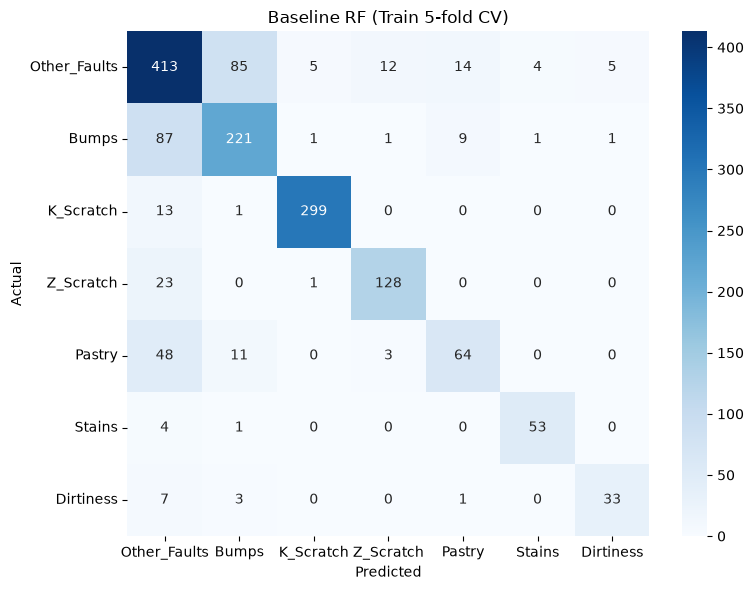

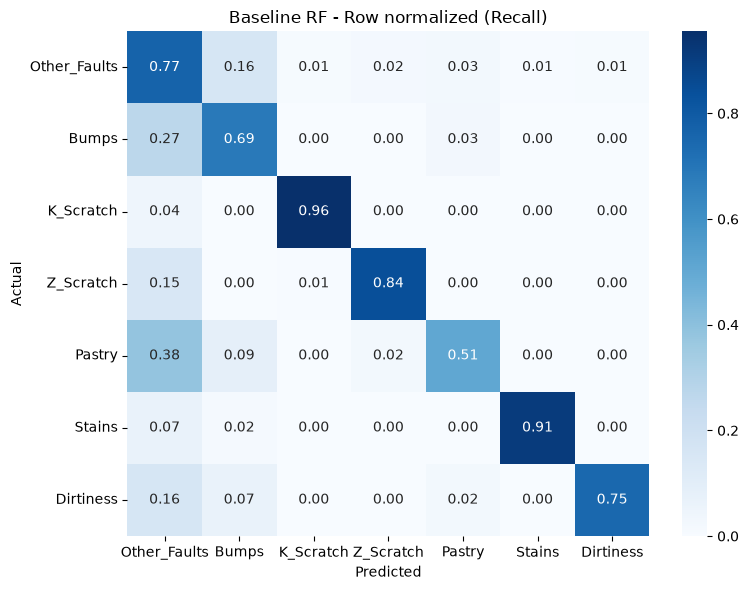


[1-1] 전체 오분류 341건
  실제 Other_Faults -> 타 클래스: 125건
  타 클래스 -> Other_Faults로 예측: 182건
  Other_Faults가 관여한 오분류 비율: 90.0%

오분류 상위 10개 쌍:
 Bumps -> Other_Faults        87
Other_Faults -> Bumps        85
Pastry -> Other_Faults       48
Z_Scratch -> Other_Faults    23
Other_Faults -> Pastry       14
K_Scratch -> Other_Faults    13
Other_Faults -> Z_Scratch    12
Pastry -> Bumps              11
Bumps -> Pastry               9
Dirtiness -> Other_Faults     7
dtype: int64

[1-2] Pastry -> Bumps: 11 | Bumps -> Pastry: 9
  Pastry 전체 오분류 중 Bumps 비중: 17.7%

Pastry vs Bumps 표준화 평균 차이 (작은 순 = 구분 어려운 변수):
 X_Maximum                0.025
X_Minimum                0.037
X_Perimeter              0.046
Outside_X_Index          0.081
Sum_of_Luminosity        0.086
Pixels_Areas             0.091
Maximum_of_Luminosity    0.122
Y_Maximum                0.127
Y_Minimum                0.127
Length_of_Conveyer       0.203
Log_X_Index              0.256
Steel_Plate_Thickness    0.268
Luminosity_Index         0.27

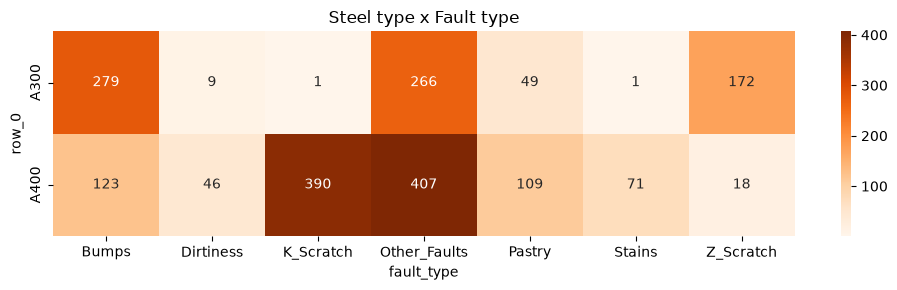


[2-2] TypeOfSteel_A300 값 분포:
 TypeOfSteel_A300
0    1164
1     777
Name: count, dtype: int64
  A300이 0/1만 가짐 -> A400(=1-A300) 제거는 정보 손실 없음

[2-3] Outside_Global_Index 고유값 수: 3
Outside_Global_Index
0.0     778
0.5      91
1.0    1072
Name: count, dtype: int64

Outside_Global_Index x 결함:
 fault_type            Bumps  Dirtiness  K_Scratch  Other_Faults  Pastry  \
Outside_Global_Index                                                      
0.0                     136          7        269           253       4   
0.5                      35          0          4            31       1   
1.0                     231         48        118           389     153   

fault_type            Stains  Z_Scratch  
Outside_Global_Index                     
0.0                       56         53  
0.5                       12          8  
1.0                        4        129  

고유값 수 적은 변수 Top 10 (범주형 후보):
 TypeOfSteel_A300           2
Outside_Global_Index       3
Steel_Plate_Thickness     24
Length_

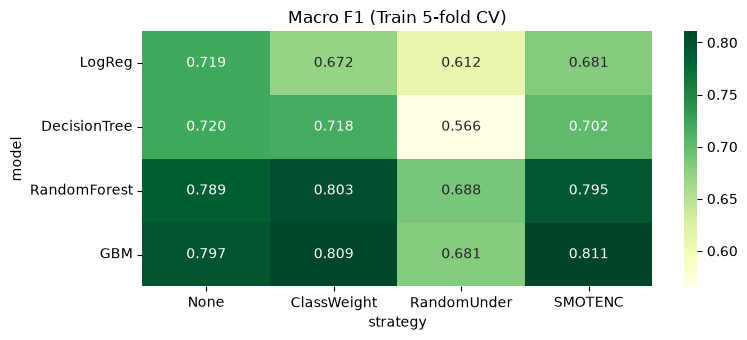


[3-2] LogReg 클래스별 Recall:
               LogReg|None  LogReg|ClassWeight  LogReg|RandomUnder  \
Other_Faults        0.677               0.403               0.314   
Bumps               0.558               0.642               0.589   
K_Scratch           0.930               0.942               0.895   
Z_Scratch           0.855               0.875               0.855   
Pastry              0.516               0.738               0.643   
Stains              0.931               0.966               1.000   
Dirtiness           0.545               0.818               0.795   

              LogReg|SMOTENC  
Other_Faults           0.411  
Bumps                  0.645  
K_Scratch              0.936  
Z_Scratch              0.855  
Pastry                 0.738  
Stains                 0.966  
Dirtiness              0.841  

[3-2] DecisionTree 클래스별 Recall:
               DecisionTree|None  DecisionTree|ClassWeight  \
Other_Faults              0.636                     0.641   
Bumps          

KeyboardInterrupt: 

shape: (1941, 27)
결측치: 0 | 전체 행 중복: 0 | 입력값 기준 중복: 0
fault_type
Other_Faults    673
Bumps           402
K_Scratch       391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
Name: count, dtype: int64
Train 클래스 분포:
 fault_type
Other_Faults    538
Bumps           321
K_Scratch       313
Z_Scratch       152
Pastry          126
Stains           58
Dirtiness        44
Name: count, dtype: int64
Test 클래스 분포:
 fault_type
Other_Faults    135
Bumps            81
K_Scratch        78
Z_Scratch        38
Pastry           32
Stains           14
Dirtiness        11
Name: count, dtype: int64


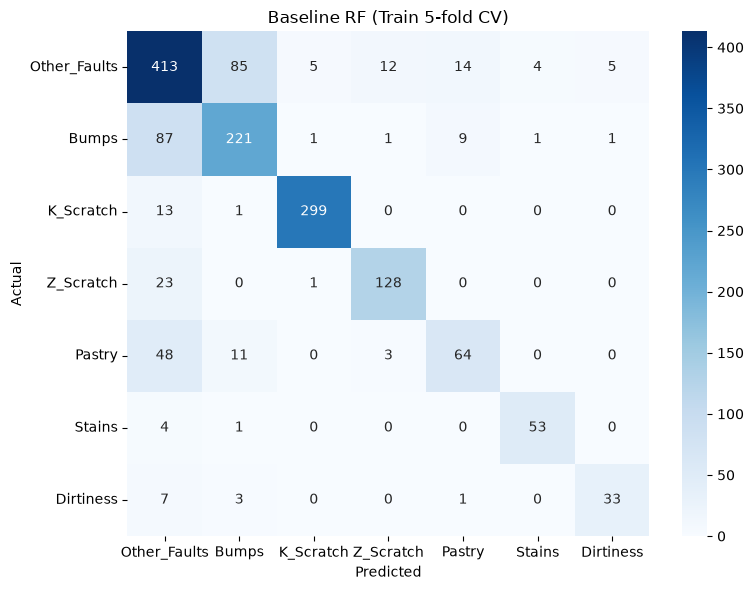

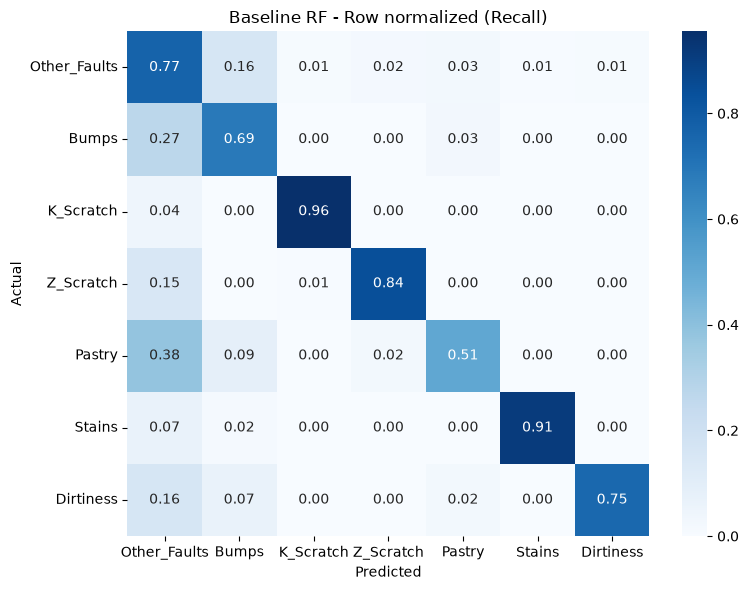


[1-1] 전체 오분류 341건
  실제 Other_Faults -> 타 클래스: 125건
  타 클래스 -> Other_Faults로 예측: 182건
  Other_Faults가 관여한 오분류 비율: 90.0%

오분류 상위 10개 쌍:
 Bumps -> Other_Faults        87
Other_Faults -> Bumps        85
Pastry -> Other_Faults       48
Z_Scratch -> Other_Faults    23
Other_Faults -> Pastry       14
K_Scratch -> Other_Faults    13
Other_Faults -> Z_Scratch    12
Pastry -> Bumps              11
Bumps -> Pastry               9
Dirtiness -> Other_Faults     7
dtype: int64

[1-2] Pastry -> Bumps: 11 | Bumps -> Pastry: 9
  Pastry 전체 오분류 중 Bumps 비중: 17.7%

Pastry vs Bumps 표준화 평균 차이 (작은 순 = 구분 어려운 변수):
 X_Maximum                0.025
X_Minimum                0.037
X_Perimeter              0.046
Outside_X_Index          0.081
Sum_of_Luminosity        0.086
Pixels_Areas             0.091
Maximum_of_Luminosity    0.122
Y_Maximum                0.127
Y_Minimum                0.127
Length_of_Conveyer       0.203
Log_X_Index              0.256
Steel_Plate_Thickness    0.268
Luminosity_Index         0.27

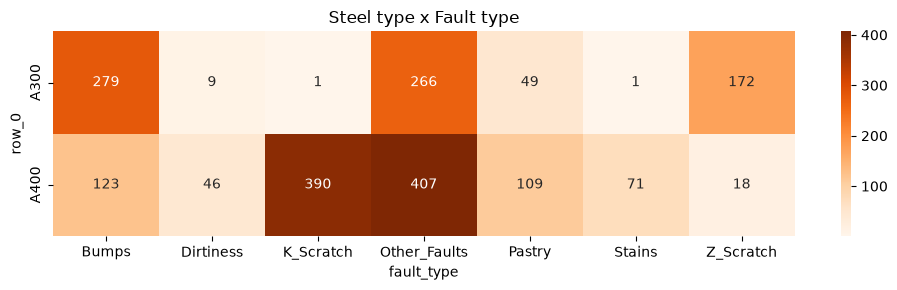


[2-2] TypeOfSteel_A300 값 분포:
 TypeOfSteel_A300
0    1164
1     777
Name: count, dtype: int64
  A300이 0/1만 가짐 -> A400(=1-A300) 제거는 정보 손실 없음

[2-3] Outside_Global_Index 고유값 수: 3
Outside_Global_Index
0.0     778
0.5      91
1.0    1072
Name: count, dtype: int64

Outside_Global_Index x 결함:
 fault_type            Bumps  Dirtiness  K_Scratch  Other_Faults  Pastry  \
Outside_Global_Index                                                      
0.0                     136          7        269           253       4   
0.5                      35          0          4            31       1   
1.0                     231         48        118           389     153   

fault_type            Stains  Z_Scratch  
Outside_Global_Index                     
0.0                       56         53  
0.5                       12          8  
1.0                        4        129  

고유값 수 적은 변수 Top 10 (범주형 후보):
 TypeOfSteel_A300           2
Outside_Global_Index       3
Steel_Plate_Thickness     24
Length_

0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0

  done: LogReg       | None        | Macro F1 0.7191
  done: LogReg       | ClassWeight | Macro F1 0.6718
  done: LogReg       | RandomUnder | Macro F1 0.6116
  done: LogReg       | SMOTENC     | Macro F1 0.6806
  done: DecisionTree | None        | Macro F1 0.7202
  done: DecisionTree | ClassWeight | Macro F1 0.7178
  done: DecisionTree | RandomUnder | Macro F1 0.5658
  done: DecisionTree | SMOTENC     | Macro F1 0.7020
  done: RandomForest | None        | Macro F1 0.7886
  done: RandomForest | ClassWeight | Macro F1 0.8030
  done: RandomForest | RandomUnder | Macro F1 0.6883
  done: RandomForest | SMOTENC     | Macro F1 0.7950
  done: GBM          | None        | Macro F1 0.7972
  done: GBM          | ClassWeight | Macro F1 0.8089
  done: GBM          | RandomUnder | Macro F1 0.6806
  done: GBM          | SMOTENC     | Macro F1 0.8107

[3-1] 4개 모델 x 불균형 처리 비교 (Train 5-fold CV):
        model    strategy  val_macroF1  val_macroF1_std  val_acc  train_macroF1  gap(train-val)  dMacroF1_vs

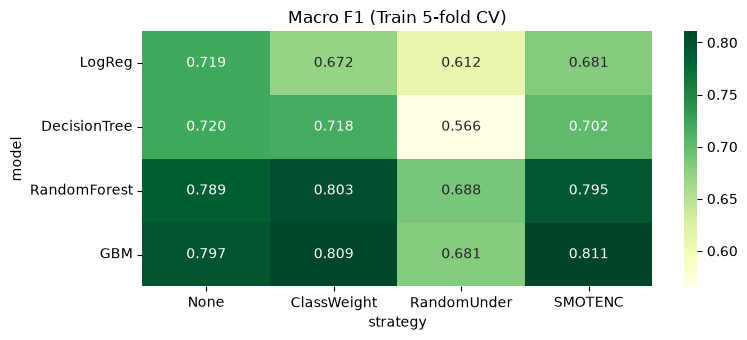


[3-2] LogReg 클래스별 Recall:
               LogReg|None  LogReg|ClassWeight  LogReg|RandomUnder  \
Other_Faults        0.677               0.403               0.314   
Bumps               0.558               0.642               0.589   
K_Scratch           0.930               0.942               0.895   
Z_Scratch           0.855               0.875               0.855   
Pastry              0.516               0.738               0.643   
Stains              0.931               0.966               1.000   
Dirtiness           0.545               0.818               0.795   

              LogReg|SMOTENC  
Other_Faults           0.411  
Bumps                  0.645  
K_Scratch              0.936  
Z_Scratch              0.855  
Pastry                 0.738  
Stains                 0.966  
Dirtiness              0.841  

[3-2] DecisionTree 클래스별 Recall:
               DecisionTree|None  DecisionTree|ClassWeight  \
Other_Faults              0.636                     0.641   
Bumps          

/Users/adj/Downloads/steel-plate-fault-classification/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/adj/Downloads/steel-plate-fault-classification/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/adj/Downloads/steel-plate-fault-classification/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to

  RandomForest (ClassWeight) best CV Macro F1 0.7963 | {'max_depth': 30, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 559}


KeyboardInterrupt: 

In [ ]:
# =====================================================================
# 논문(Ozkat, 2022) 참고사항 역할별 확인 코드
# 대상 파일: data/processed/Faults_processed.csv
# 필요 패키지: pip install pandas numpy scikit-learn imbalanced-learn matplotlib seaborn tabulate
# Jupyter에서는 "# %%" 단위로 셀을 나눠 실행하면 됩니다.
# 주의: 모든 확인은 Train 데이터(또는 Train 내부 CV)에서만 수행합니다. Test는 건드리지 않습니다.
# =====================================================================

# %% [0] 공통 설정 · 데이터 로드 · 라벨 생성 · 분할
import os
os.environ["PYTHONWARNINGS"] = "ignore::UserWarning"   # 병렬 작업 경고 숨김
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_val_predict, cross_val_score, cross_validate,
                                     RandomizedSearchCV)
from sklearn.metrics import confusion_matrix, f1_score, recall_score
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from scipy.stats import randint, uniform

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE, SMOTENC
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore")
RS = 42
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

DATA_PATH = "/Users/adj/Downloads/steel-plate-fault-classification/data/processed/Faults_processed.csv"
LABEL_COL = "target"

# Faults_processed.csv 구조: 입력 26개 + target(문자열 라벨)
#  - 정답 7개 열은 이미 target 하나로 합쳐져 있음
#  - TypeOfSteel_A400은 이미 제거됨 (A300과 보완 관계라 중복)
#  - 클래스명 오타 K_Scatch -> K_Scratch로 수정되어 있음
FEATURES = ["X_Minimum", "X_Maximum", "Y_Minimum", "Y_Maximum", "Pixels_Areas",
            "X_Perimeter", "Y_Perimeter", "Sum_of_Luminosity", "Minimum_of_Luminosity",
            "Maximum_of_Luminosity", "Length_of_Conveyer", "TypeOfSteel_A300",
            "Steel_Plate_Thickness", "Edges_Index", "Empty_Index",
            "Square_Index", "Outside_X_Index", "Edges_X_Index", "Edges_Y_Index",
            "Outside_Global_Index", "LogOfAreas", "Log_X_Index", "Log_Y_Index",
            "Orientation_Index", "Luminosity_Index", "SigmoidOfAreas"]

df = pd.read_csv(DATA_PATH)
print("shape:", df.shape)

missing = [c for c in FEATURES + [LABEL_COL] if c not in df.columns]
assert not missing, f"파일에 없는 열: {missing}"
print("결측치:", df.isna().sum().sum(), "| 전체 행 중복:", df.duplicated().sum(),
      "| 입력값 기준 중복:", df[FEATURES].duplicated().sum())

df["fault_type"] = df[LABEL_COL]
X = df[FEATURES].copy()          # target / fault_type은 X에서 제외
y = df["fault_type"]
print(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RS)

CLASSES = y.value_counts().index.tolist()   # 많은 순서
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

print("Train 클래스 분포:\n", y_train.value_counts())
print("Test 클래스 분포:\n", y_test.value_counts())


def plot_cm(cm, labels, title, fname, normalize=False):
    data = cm.astype(float) / cm.sum(axis=1, keepdims=True) if normalize else cm
    plt.figure(figsize=(8, 6))
    sns.heatmap(data, annot=True, fmt=".2f" if normalize else "d",
                xticklabels=labels, yticklabels=labels, cmap="Blues")
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(title)
    plt.tight_layout(); plt.savefig(f"{OUT}/{fname}", dpi=150); plt.show()


# =====================================================================
# %% [1] 문제 정의 담당
#   1-1. Other_Faults가 오분류에 얼마나 관여하는가 (혼합 클래스 가설)
#   1-2. Pastry <-> Bumps 혼동 가설
#   1-3. (참고) 6클래스 vs 7클래스 Macro F1 비교
# =====================================================================
rf_base = RandomForestClassifier(n_estimators=300, random_state=RS, n_jobs=-1)
y_pred_cv = cross_val_predict(rf_base, X_train, y_train, cv=cv)

cm = confusion_matrix(y_train, y_pred_cv, labels=CLASSES)
plot_cm(cm, CLASSES, "Baseline RF (Train 5-fold CV)", "1_cm_baseline.png")
plot_cm(cm, CLASSES, "Baseline RF - Row normalized (Recall)", "1_cm_baseline_norm.png", normalize=True)

off = cm.copy()
np.fill_diagonal(off, 0)
off_df = pd.DataFrame(off, index=CLASSES, columns=CLASSES)

# 1-1. Other_Faults 관여 오분류 비율
total_err = off_df.values.sum()
other_as_actual = off_df.loc["Other_Faults"].sum()     # 실제 Other -> 다른 클래스
other_as_pred = off_df["Other_Faults"].sum()           # 다른 클래스 -> Other로 예측
print(f"\n[1-1] 전체 오분류 {total_err}건")
print(f"  실제 Other_Faults -> 타 클래스: {other_as_actual}건")
print(f"  타 클래스 -> Other_Faults로 예측: {other_as_pred}건")
print(f"  Other_Faults가 관여한 오분류 비율: {(other_as_actual + other_as_pred) / total_err:.1%}")

# 혼동 쌍 상위 10개 (실제 -> 예측)
pairs = off_df.stack().sort_values(ascending=False)
pairs.index = [f"{a} -> {p}" for a, p in pairs.index]
print("\n오분류 상위 10개 쌍:\n", pairs.head(10))

# 1-2. Pastry <-> Bumps
print("\n[1-2] Pastry -> Bumps:", off_df.loc["Pastry", "Bumps"],
      "| Bumps -> Pastry:", off_df.loc["Bumps", "Pastry"])
print("  Pastry 전체 오분류 중 Bumps 비중:",
      f"{off_df.loc['Pastry', 'Bumps'] / off_df.loc['Pastry'].sum():.1%}")

# 두 클래스의 특징 차이 (표준화 평균 차이가 작을수록 구분이 어려움)
tr = X_train.assign(fault_type=y_train)
pb = tr[tr["fault_type"].isin(["Pastry", "Bumps"])]
std_diff = ((pb[pb.fault_type == "Pastry"][FEATURES].mean() - pb[pb.fault_type == "Bumps"][FEATURES].mean())
            / X_train[FEATURES].std()).abs().sort_values()
print("\nPastry vs Bumps 표준화 평균 차이 (작은 순 = 구분 어려운 변수):\n", std_diff.round(3))

# 1-3. 6클래스 vs 7클래스 (참고 실험, 메인 결과는 7클래스)
mask = y_train != "Other_Faults"
f1_7 = cross_val_score(rf_base, X_train, y_train, cv=cv, scoring="f1_macro")
f1_6 = cross_val_score(rf_base, X_train[mask], y_train[mask], cv=cv, scoring="f1_macro")
print(f"\n[1-3] 7클래스 Macro F1: {f1_7.mean():.4f} ± {f1_7.std():.4f}")
print(f"      6클래스 Macro F1: {f1_6.mean():.4f} ± {f1_6.std():.4f}  (Other_Faults 제외, 참고용)")


# =====================================================================
# %% [2] 데이터 분석·전처리 담당
#   2-1. 강종 x 결함 교차표
#   2-2. A300 / A400 중복(보완 관계) 여부
#   2-3. Outside_Global_Index 범주형 여부 + 저카디널리티 변수 스캔
#   2-4. 파생 변수 간 높은 상관 확인
# =====================================================================
# 2-1. 강종 x 결함 (EDA이므로 전체 df 사용)
steel = np.where(df["TypeOfSteel_A300"] == 1, "A300", "A400")   # A400 열은 제거됨 -> A300=0이면 A400
ct = pd.crosstab(steel, df["fault_type"], margins=True)
print("\n[2-1] 강종 x 결함 건수:\n", ct)

ct_ratio = pd.crosstab(steel, df["fault_type"], normalize="columns").round(3)
print("\n결함 유형별 강종 비율 (열 기준):\n", ct_ratio)

plt.figure(figsize=(10, 3))
sns.heatmap(pd.crosstab(steel, df["fault_type"]), annot=True, fmt="d", cmap="Oranges")
plt.title("Steel type x Fault type"); plt.tight_layout()
plt.savefig(f"{OUT}/2_steel_x_fault.png", dpi=150); plt.show()

# 2-2. A300 / A400 중복 여부
#   처리 파일에는 A400이 이미 제거되어 있음 -> A300이 0/1만 갖는지만 확인
#   (원본에서 A300 + A400 = 1 인지 확인하려면 raw 파일로 검증 후 README에 근거 기록)
print("\n[2-2] TypeOfSteel_A300 값 분포:\n", df["TypeOfSteel_A300"].value_counts())
assert set(df["TypeOfSteel_A300"].unique()) <= {0, 1}, "A300에 0/1 외 값 존재"
print("  A300이 0/1만 가짐 -> A400(=1-A300) 제거는 정보 손실 없음")

# 2-3. Outside_Global_Index
print("\n[2-3] Outside_Global_Index 고유값 수:", df["Outside_Global_Index"].nunique())
print(df["Outside_Global_Index"].value_counts().sort_index())
print("\nOutside_Global_Index x 결함:\n", pd.crosstab(df["Outside_Global_Index"], df["fault_type"]))

print("\n고유값 수 적은 변수 Top 10 (범주형 후보):\n", X.nunique().sort_values().head(10))

# 2-4. 면적·둘레·밝기 파생 변수 상관
area_cols = ["Pixels_Areas", "LogOfAreas", "SigmoidOfAreas", "X_Perimeter",
             "Y_Perimeter", "Sum_of_Luminosity"]
print("\n[2-4] 면적 관련 변수 Spearman 상관:\n", X_train[area_cols].corr(method="spearman").round(3))

corr = X_train.corr(method="spearman").abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high = upper.stack().sort_values(ascending=False)
print("\n|r| > 0.9 변수 쌍:\n", high[high > 0.9])


# =====================================================================
# %% [3] 모델링·불균형 처리 담당
#   발제문 지정 4개 모델 x 불균형 처리 4가지 (같은 5-fold CV로 비교)
#   - None        : 처리 없음 (Baseline)
#   - ClassWeight : LR/DT/RF는 class_weight="balanced", GBM은 sample_weight로 동일 효과
#   - RandomUnder : 다수 클래스를 최소 클래스 수에 맞춰 축소
#   - SMOTENC     : 범주형(TypeOfSteel_A300, Outside_Global_Index)을 지정한 SMOTE
#   ※ Pipeline 안에서 [표준화 -> 샘플링 -> 모델] 순서 -> 각 Fold의 학습 데이터에만 적용
#   ※ 표준화를 샘플링보다 먼저 하는 이유: SMOTE는 거리로 이웃을 찾는데,
#     Y_Minimum(수백만 단위)처럼 큰 변수가 거리를 독점하지 않게 하려고
# =====================================================================
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.base import clone
from scipy.stats import loguniform

CAT_COLS = ["TypeOfSteel_A300", "Outside_Global_Index"]          # [2-3]에서 확정
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]
Xtr = X_train[NUM_COLS + CAT_COLS]                               # 열 순서 고정: 수치 -> 범주
Xte = X_test[NUM_COLS + CAT_COLS]
CAT_IDX = list(range(len(NUM_COLS), len(NUM_COLS) + len(CAT_COLS)))   # 표준화 후 범주형 위치


def make_scaler():
    # 수치형만 표준화, 범주형은 그대로 통과 (뒤쪽에 붙음)
    return ColumnTransformer([("num", StandardScaler(), NUM_COLS)], remainder="passthrough")


class BalancedGBM(GradientBoostingClassifier):
    """sklearn GBM에는 class_weight가 없어서, fit 할 때마다 그 Fold의 y로
    'balanced' sample_weight를 계산해 넣는 버전 (노션 안내: GBM 가중치는 sample_weight로)"""
    def fit(self, X, y, sample_weight=None):
        return super().fit(X, y, sample_weight=compute_sample_weight("balanced", y))


def build_model(name, balanced=False):
    cw = "balanced" if balanced else None
    if name == "LogReg":
        return LogisticRegression(max_iter=3000, class_weight=cw, random_state=RS)
    if name == "DecisionTree":
        return DecisionTreeClassifier(class_weight=cw, random_state=RS)
    if name == "RandomForest":
        return RandomForestClassifier(n_estimators=300, class_weight=cw, random_state=RS, n_jobs=-1)
    if name == "GBM":
        return BalancedGBM(random_state=RS) if balanced else GradientBoostingClassifier(random_state=RS)
    raise ValueError(name)


# SMOTENC 이웃 수: 가장 작은 클래스의 '한 Fold 학습 데이터' 건수보다 작아야 함
min_cnt = y_train.value_counts().min()
min_in_fold = int(min_cnt * (cv.get_n_splits() - 1) / cv.get_n_splits())
K = min(5, min_in_fold - 1)
print(f"\n[3] 최소 클래스 Train {min_cnt}건, Fold 내 약 {min_in_fold}건 -> SMOTENC k_neighbors={K}")

STRATEGIES = {
    "None":        (None, False),
    "ClassWeight": (None, True),
    "RandomUnder": (RandomUnderSampler(random_state=RS), False),
    "SMOTENC":     (SMOTENC(categorical_features=CAT_IDX, k_neighbors=K, random_state=RS), False),
}
MODELS = ["LogReg", "DecisionTree", "RandomForest", "GBM"]


def make_pipe(model_name, strategy, model=None):
    sampler, balanced = STRATEGIES[strategy]
    steps = [("scaler", make_scaler())]
    if sampler is not None:
        steps.append(("sampler", clone(sampler)))
    steps.append(("model", model if model is not None else build_model(model_name, balanced)))
    return ImbPipeline(steps)


rows, cv_preds = [], {}
for m in MODELS:
    for s in STRATEGIES:
        pipe = make_pipe(m, s)
        res = cross_validate(pipe, Xtr, y_train, cv=cv, return_train_score=True, n_jobs=-1,
                             scoring={"f1_macro": "f1_macro", "acc": "accuracy"})
        cv_preds[(m, s)] = cross_val_predict(pipe, Xtr, y_train, cv=cv, n_jobs=-1)
        rows.append({"model": m, "strategy": s,
                     "val_macroF1": res["test_f1_macro"].mean(),
                     "val_macroF1_std": res["test_f1_macro"].std(),
                     "val_acc": res["test_acc"].mean(),
                     "train_macroF1": res["train_f1_macro"].mean()})
        print(f"  done: {m:12s} | {s:11s} | Macro F1 {rows[-1]['val_macroF1']:.4f}")

cmp_df = pd.DataFrame(rows)
cmp_df["gap(train-val)"] = cmp_df["train_macroF1"] - cmp_df["val_macroF1"]
base = cmp_df[cmp_df.strategy == "None"].set_index("model")["val_macroF1"]
cmp_df["dMacroF1_vs_None"] = cmp_df["val_macroF1"] - cmp_df["model"].map(base)
cmp_df = cmp_df.round(4)
print("\n[3-1] 4개 모델 x 불균형 처리 비교 (Train 5-fold CV):\n",
      cmp_df.to_string(index=False))
cmp_df.to_csv(f"{OUT}/3_model_strategy_compare.csv", index=False)

# 표로 한눈에: 행=모델, 열=처리 방법
pivot = cmp_df.pivot(index="model", columns="strategy", values="val_macroF1").loc[MODELS, list(STRATEGIES)]
plt.figure(figsize=(8, 3.5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGn")
plt.title("Macro F1 (Train 5-fold CV)"); plt.tight_layout()
plt.savefig(f"{OUT}/3_macroF1_heatmap.png", dpi=150); plt.show()

# 클래스별 Recall / F1 (처리 전후 변화 확인용)
recall_tbl = pd.DataFrame({f"{m}|{s}": recall_score(y_train, p, labels=CLASSES, average=None)
                           for (m, s), p in cv_preds.items()}, index=CLASSES).round(3)
f1_tbl = pd.DataFrame({f"{m}|{s}": f1_score(y_train, p, labels=CLASSES, average=None)
                       for (m, s), p in cv_preds.items()}, index=CLASSES).round(3)
recall_tbl.to_csv(f"{OUT}/3_per_class_recall.csv")
f1_tbl.to_csv(f"{OUT}/3_per_class_f1.csv")
for m in MODELS:
    print(f"\n[3-2] {m} 클래스별 Recall:\n", recall_tbl[[f"{m}|{s}" for s in STRATEGIES]])

# 주요 혼동 쌍 건수 변화 (논문 Pastry<->Bumps + 우리 데이터에서 확인된 Bumps<->Other)
PAIRS = [("Bumps", "Other_Faults"), ("Other_Faults", "Bumps"),
         ("Pastry", "Bumps"), ("Bumps", "Pastry"), ("Pastry", "Other_Faults")]
pair_rows = []
for (m, s), p in cv_preds.items():
    cm_ = pd.DataFrame(confusion_matrix(y_train, p, labels=CLASSES), index=CLASSES, columns=CLASSES)
    pair_rows.append({"model": m, "strategy": s, **{f"{a}->{b}": cm_.loc[a, b] for a, b in PAIRS}})
pair_df = pd.DataFrame(pair_rows)
print("\n[3-3] 주요 혼동 쌍 건수:\n", pair_df.to_string(index=False))
pair_df.to_csv(f"{OUT}/3_confusion_pairs.csv", index=False)

# 처리 후 클래스별 건수 기록 (README용)
counts = {"Original": y_train.value_counts()}
for s, (sampler, _) in STRATEGIES.items():
    if sampler is not None:
        Xs_ = make_scaler().fit_transform(Xtr)
        _, y_res = clone(sampler).fit_resample(Xs_, y_train)
        counts[s] = pd.Series(y_res).value_counts()
print("\n[3-4] 처리 후 클래스별 학습 건수:\n", pd.DataFrame(counts).loc[CLASSES])

# ClassWeight 실제 가중치 (README용)
w = pd.Series(compute_sample_weight("balanced", y_train), index=y_train.index).groupby(y_train).first()
print("\n  클래스별 balanced 가중치:\n", w.loc[CLASSES].round(3))

# 로지스틱 회귀 수렴 확인 (노션: 기존 LR에 수렴 경고가 있었음)
lr_pipe = make_pipe("LogReg", "None").fit(Xtr, y_train)
n_iter = lr_pipe.named_steps["model"].n_iter_.max()
print(f"\n  LogReg 반복 횟수 {n_iter} / max_iter 3000 -> {'수렴' if n_iter < 3000 else '미수렴! max_iter 늘리기'}")


# =====================================================================
# %% [4] 모델링·튜닝 담당
#   각 모델의 [3]에서 가장 좋았던 처리 방법을 고정하고 하이퍼파라미터 탐색
#   RF 범위에는 논문 최적값(트리 300개, min_samples_leaf 1)을 포함
#   ※ Test 데이터는 사용하지 않음 (Train 내부 5-fold CV만)
# =====================================================================
best_strategy = cmp_df.loc[cmp_df.groupby("model")["val_macroF1"].idxmax()].set_index("model")["strategy"]
print("\n[4] 모델별 [3] 최고 처리 방법:\n", best_strategy)

SEARCH_SPACE = {
    "LogReg": {"model__C": loguniform(1e-3, 1e2)},
    "DecisionTree": {"model__max_depth": [None, 5, 10, 15, 20],
                     "model__min_samples_leaf": randint(1, 20),
                     "model__criterion": ["gini", "entropy"]},
    "RandomForest": {"model__n_estimators": randint(100, 600),
                     "model__min_samples_leaf": randint(1, 10),
                     "model__max_depth": [None, 10, 20, 30],
                     "model__max_features": ["sqrt", "log2", 0.5]},
    "GBM": {"model__n_estimators": randint(100, 500),
            "model__learning_rate": loguniform(0.01, 0.3),
            "model__max_depth": randint(2, 6),
            "model__subsample": uniform(0.6, 0.4)},
}
N_ITER = {"LogReg": 20, "DecisionTree": 30, "RandomForest": 20, "GBM": 20}

tuned, tune_rows = {}, []
for m in MODELS:
    s = best_strategy[m]
    search = RandomizedSearchCV(make_pipe(m, s), SEARCH_SPACE[m], n_iter=N_ITER[m],
                                scoring="f1_macro", cv=cv, random_state=RS, n_jobs=-1,
                                return_train_score=True)
    search.fit(Xtr, y_train)
    tuned[m] = search
    best_i = search.best_index_
    tune_rows.append({"model": m, "strategy": s,
                      "before_tuning": cmp_df.query("model == @m and strategy == @s")["val_macroF1"].iloc[0],
                      "after_tuning": search.best_score_,
                      "after_std": search.cv_results_["std_test_score"][best_i],
                      "train_macroF1": search.cv_results_["mean_train_score"][best_i],
                      "best_params": {k.replace("model__", ""): v for k, v in search.best_params_.items()}})
    pd.DataFrame(search.cv_results_).sort_values("rank_test_score")[
        ["params", "mean_test_score", "std_test_score", "mean_train_score", "rank_test_score"]
    ].to_csv(f"{OUT}/4_tuning_{m}.csv", index=False)
    print(f"  {m:12s} ({s}) best CV Macro F1 {search.best_score_:.4f} | {tune_rows[-1]['best_params']}")

tune_df = pd.DataFrame(tune_rows)
tune_df["gain"] = tune_df["after_tuning"] - tune_df["before_tuning"]
tune_df["gap(train-val)"] = tune_df["train_macroF1"] - tune_df["after_tuning"]
print("\n[4] 튜닝 전후:\n", tune_df.round(4).to_string(index=False))
tune_df.to_csv(f"{OUT}/4_tuning_summary.csv", index=False)

# 탐색 범위 끝에 걸린 파라미터 경고 (범위를 넓혀야 할 수도 있음)
EDGES = {"RandomForest": {"n_estimators": (100, 599), "min_samples_leaf": (1, 9)},
         "GBM": {"n_estimators": (100, 499), "max_depth": (2, 5)},
         "DecisionTree": {"min_samples_leaf": (1, 19)}}
for m, edges in EDGES.items():
    bp = tune_df.set_index("model").loc[m, "best_params"]
    for p, (lo, hi) in edges.items():
        if p in bp and (bp[p] <= lo or bp[p] >= hi * 0.97):
            print(f"  ⚠ {m}.{p}={bp[p]} 이 탐색 범위 끝에 있음 -> 범위를 넓혀 재탐색 권장")


# =====================================================================
# %% [5] 평가·결과 분석 담당
#   최종 후보(튜닝 후 CV Macro F1 최고)의 처리 전후 Confusion Matrix 비교
#   + 반복 층화 CV로 클래스별 성능 불확실성
#   ※ ★ [3], [4] 결과가 있어야 실행 가능 ★
# =====================================================================
final_name = tune_df.loc[tune_df["after_tuning"].idxmax(), "model"]
final_pipe = tuned[final_name].best_estimator_
print(f"\n[5] 최종 후보: {final_name} + {best_strategy[final_name]} (튜닝 후)")

pred_before = cv_preds[(final_name, "None")]
pred_after = cross_val_predict(clone(final_pipe), Xtr, y_train, cv=cv, n_jobs=-1)
cm_before = confusion_matrix(y_train, pred_before, labels=CLASSES)
cm_after = confusion_matrix(y_train, pred_after, labels=CLASSES)

plot_cm(cm_before, CLASSES, f"{final_name} Baseline (Train CV)", "5_cm_before.png")
plot_cm(cm_after, CLASSES, f"{final_name} final (Train CV)", "5_cm_after.png")
diff = pd.DataFrame(cm_after - cm_before, index=CLASSES, columns=CLASSES)
plt.figure(figsize=(8, 6))
sns.heatmap(diff, annot=True, fmt="d", cmap="RdBu", center=0)
plt.title("Confusion Matrix change (final - baseline)"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.savefig(f"{OUT}/5_cm_diff.png", dpi=150); plt.show()

per_class = pd.DataFrame({
    "recall_before": recall_score(y_train, pred_before, labels=CLASSES, average=None),
    "recall_after": recall_score(y_train, pred_after, labels=CLASSES, average=None),
    "f1_before": f1_score(y_train, pred_before, labels=CLASSES, average=None),
    "f1_after": f1_score(y_train, pred_after, labels=CLASSES, average=None)}, index=CLASSES)
per_class["d_recall"] = per_class["recall_after"] - per_class["recall_before"]
per_class["d_f1"] = per_class["f1_after"] - per_class["f1_before"]
print("\n[5-1] 클래스별 처리 전후 (개선 + / 악화 -):\n", per_class.round(3))
per_class.round(4).to_csv(f"{OUT}/5_per_class_before_after.csv")

# 반복 층화 CV (시간이 오래 걸리면 n_repeats를 줄이세요)
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RS)
per_fold = []
for tr_idx, va_idx in rskf.split(Xtr, y_train):
    p = clone(final_pipe).fit(Xtr.iloc[tr_idx], y_train.iloc[tr_idx]).predict(Xtr.iloc[va_idx])
    per_fold.append(f1_score(y_train.iloc[va_idx], p, labels=CLASSES, average=None))
per_fold = pd.DataFrame(per_fold, columns=CLASSES)
unc = per_fold.agg(["mean", "std", "min", "max"]).T.round(3)
unc["test_n"] = y_test.value_counts()[CLASSES].values
unc["1건당_recall_변동(%p)"] = (100 / unc["test_n"]).round(1)
print("\n[5-2] 최종 후보 클래스별 F1 불확실성 (5-fold x 5회):\n", unc)
unc.to_csv(f"{OUT}/5_rare_class_uncertainty.csv")


# =====================================================================
# %% [7] 최종 Test 평가 (모델 선정이 끝난 뒤 '딱 한 번'만)
#   팀에서 최종 모델을 확정한 후 RUN_FINAL_TEST = True 로 바꿔 실행
# =====================================================================
RUN_FINAL_TEST = False
if RUN_FINAL_TEST:
    from sklearn.metrics import classification_report, accuracy_score
    final_fit = clone(final_pipe).fit(Xtr, y_train)
    y_pred_test = final_fit.predict(Xte)
    print(f"\n[7] Test 결과 - {final_name}")
    print("Accuracy:", round(accuracy_score(y_test, y_pred_test), 4),
          "| Macro F1:", round(f1_score(y_test, y_pred_test, average="macro"), 4))
    print(classification_report(y_test, y_pred_test, labels=CLASSES, digits=3))
    plot_cm(confusion_matrix(y_test, y_pred_test, labels=CLASSES), CLASSES,
            f"{final_name} - TEST", "7_cm_test.png")
else:
    print("\n[7] 최종 Test 평가는 모델 확정 후 RUN_FINAL_TEST=True 로 실행하세요.")


# =====================================================================
# %% [6] 문서화 담당
#   6-1. 선행 연구 표 (논문 Table 7 발췌 + 조건 차이 명시)
#   6-2. 인용 문구
# =====================================================================
related = pd.DataFrame([
    ["Fakhr & Elsayad (2012)", "DT", 97.25, "7", "-"],
    ["Tian et al. (2015)", "GS-SVM", 77.7, "6 (Other 제외)", "-"],
    ["Zhao et al. (2015)", "NN", 88.05, "-", "LOF 이상치 제거"],
    ["Chen (2018)", "RF", 90.29, "6 (Other 제외)", "10-fold CV"],
    ["Kharal (2020)", "RF", 91.25, "-", "Under/Over/SMOTE 비교"],
    ["Gamal et al. (2021)", "RF", 91.29, "6 (Other 제외)", "50:50 분할"],
    ["Tasar (2022)", "NN", None, "-", "Train/Test 분할 없음"],
    ["Ozkat (2022)", "AdaBoost", 91.90, "6 (Other 제외)", "1,239건으로 필터링, PCA 변수선택 (AdaBoost는 참고용)"],
], columns=["연구", "최고 모델", "Test Accuracy(%)", "클래스 수", "비고"])
related["우리와 비교 가능"] = "X (클래스·데이터·지표 상이)"
print("\n[6-1] 선행 연구:\n", related)
try:
    with open(f"{OUT}/6_related_work.md", "w", encoding="utf-8") as f:
        f.write(related.to_markdown(index=False))
except ImportError:
    related.to_csv(f"{OUT}/6_related_work.csv", index=False, encoding="utf-8-sig")

citation = ("Ozkat, E. C. (2022). A Method to Classify Steel Plate Faults Based on Ensemble Learning. "
            "Journal of Materials and Mechatronics: A (JournalMM), 3(2), 240-256. "
            "https://doi.org/10.55546/jmm.1161542")
print("\n[6-2] 인용:\n", citation)

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTENC, SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# ---------------------------------------------------------
# 1. 데이터 로드 및 Target 처리 (자동 감지 로직)
# ---------------------------------------------------------
file_path = '/Users/adj/Downloads/steel-plate-fault-classification/data/processed/Faults_processed.csv'

if not os.path.exists(file_path):
    raise FileNotFoundError(f"파일을 찾을 수 없습니다: {file_path}")

df = pd.read_csv(file_path)

# 원-핫 정답 열 7개 명단
target_cols = ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']

# Target y 및 Feature X 분리
if 'fault_type' in df.columns:
    y = df['fault_type']
    drop_cols = [col for col in target_cols + ['fault_type'] if col in df.columns]
    X_raw = df.drop(columns=drop_cols)
elif all(col in df.columns for col in target_cols):
    df['fault_type'] = df[target_cols].idxmax(axis=1)
    y = df['fault_type']
    X_raw = df.drop(columns=target_cols + ['fault_type'])
else:
    y = df.iloc[:, -1]
    X_raw = df.iloc[:, :-1]

print(f"데이터 로드 완료 - X 모양: {X_raw.shape}, Target 클래스 수: {len(y.unique())}")

# ---------------------------------------------------------
# 2. Feature Engineering (기본 vs 파생 변수 추가)
# ---------------------------------------------------------
X_engineered = X_raw.copy()

if {'X_Perimeter', 'Y_Perimeter', 'Pixels_Areas'}.issubset(X_engineered.columns):
    X_engineered['Border_Complexity'] = (X_engineered['X_Perimeter'] + X_engineered['Y_Perimeter']) / (X_engineered['Pixels_Areas'] + 1e-5)

if {'Sum_of_Luminosity', 'Pixels_Areas'}.issubset(X_engineered.columns):
    X_engineered['Luminosity_Density'] = X_engineered['Sum_of_Luminosity'] / (X_engineered['Pixels_Areas'] + 1e-5)

if {'Outside_X_Index', 'Y_Maximum', 'Y_Minimum'}.issubset(X_engineered.columns):
    X_engineered['Aspect_Ratio'] = X_engineered['Outside_X_Index'] / (X_engineered['Y_Maximum'] - X_engineered['Y_Minimum'] + 1)

# Outside_Global_Index 범주형 열 위치 지정 (SMOTENC용)
cat_col_name = 'Outside_Global_Index'
if cat_col_name in X_engineered.columns:
    categorical_features = [X_engineered.columns.get_loc(cat_col_name)]
else:
    categorical_features = []

# ---------------------------------------------------------
# 3. Train / Test 80:20 층화 분할
# ---------------------------------------------------------
X_train_base, X_test_base, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y
)
X_train_eng, X_test_eng, _, _ = train_test_split(
    X_engineered, y, test_size=0.2, random_state=42, stratify=y
)

# StratifiedKFold 5-Fold 객체 생성
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ---------------------------------------------------------
# 4. [Baseline 모델] 생성, 5-Fold CV 검증 및 Test 평가
# ---------------------------------------------------------
base_rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Train 내부 5-Fold CV 수행 (f1_macro 정식 표기)
cv_base = cross_validate(base_rf, X_train_base, y_train, cv=skf, scoring='f1_macro')
base_cv_mean = cv_base['test_score'].mean()
base_cv_std = cv_base['test_score'].std()

# Test 세트 최종 평가
base_rf.fit(X_train_base, y_train)
y_pred_base = base_rf.predict(X_test_base)

base_acc = accuracy_score(y_test, y_pred_base)
base_macro_f1 = f1_score(y_test, y_pred_base, average='macro')
base_weighted_f1 = f1_score(y_test, y_pred_base, average='weighted')

# ---------------------------------------------------------
# 5. [Advanced 모델] 변수(adv_pipe) 선선언 후 5-Fold CV 검증
# ---------------------------------------------------------
# SMOTENC / SMOTE 설정
if len(categorical_features) > 0:
    smote_step = SMOTENC(categorical_features=categorical_features, k_neighbors=3, random_state=42)
else:
    smote_step = SMOTE(k_neighbors=3, random_state=42)

# 튜닝된 RF 모델
adv_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=2,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

# adv_pipe 변수 생성 (cv 실행 전에 먼저 선언되어야 함)
adv_pipe = ImbPipeline([
    ('smote', smote_step),
    ('rf', adv_rf)
])

# Train 내부 5-Fold CV 수행 (f1_macro 정식 표기)
cv_adv = cross_validate(adv_pipe, X_train_eng, y_train, cv=skf, scoring='f1_macro')
adv_cv_mean = cv_adv['test_score'].mean()
adv_cv_std = cv_adv['test_score'].std()

# Test 세트 최종 평가
adv_pipe.fit(X_train_eng, y_train)
y_pred_adv = adv_pipe.predict(X_test_eng)

adv_acc = accuracy_score(y_test, y_pred_adv)
adv_macro_f1 = f1_score(y_test, y_pred_adv, average='macro')
adv_weighted_f1 = f1_score(y_test, y_pred_adv, average='weighted')

# ---------------------------------------------------------
# 6. 최종 비교 결과 종합 출력
# ---------------------------------------------------------
print("\n==========================================================================")
print("                       모델 검증 및 성능 평가 종합 결과                   ")
print("==========================================================================")
print(f"1. Baseline 모델 (기본 RF):")
print(f"   - Accuracy (정확도)      : {base_acc:.4f}")
print(f"   - Macro F1 (전체 예측)   : {base_macro_f1:.4f}")
print(f"   - Weighted F1            : {base_weighted_f1:.4f}")
print(f"   - 5-Fold CV 평균 Macro F1: {base_cv_mean:.4f}")
print(f"   - 5-Fold CV 표준편차     : {base_cv_std:.4f}\n")

print(f"2. Advanced 모델 (파생변수 + SMOTENC + RF 튜닝):")
print(f"   - Accuracy (정확도)      : {adv_acc:.4f}")
print(f"   - Macro F1 (전체 예측)   : {adv_macro_f1:.4f}")
print(f"   - Weighted F1            : {adv_weighted_f1:.4f}")
print(f"   - 5-Fold CV 평균 Macro F1: {adv_cv_mean:.4f}")
print(f"   - 5-Fold CV 표준편차     : {adv_cv_std:.4f}\n")

print(f"3. 성능 변화량 (Advanced - Baseline):")
print(f"   - Accuracy 증감          : {adv_acc - base_acc:+.4f} ({(adv_acc - base_acc)*100:+.2f}%p)")
print(f"   - Macro F1 증감          : {adv_macro_f1 - base_macro_f1:+.4f} ({(adv_macro_f1 - base_macro_f1)*100:+.2f}%p)")
print(f"   - Weighted F1 증감       : {adv_weighted_f1 - base_weighted_f1:+.4f} ({(adv_weighted_f1 - base_weighted_f1)*100:+.2f}%p)")
print(f"   - CV 평균 Macro F1 증감  : {adv_cv_mean - base_cv_mean:+.4f} ({(adv_cv_mean - base_cv_mean)*100:+.2f}%p)")
print(f"   - CV 표준편차 증감       : {adv_cv_std - base_cv_std:+.4f} (변동성 감소/안정성 개선)")
print("==========================================================================\n")

데이터 로드 완료 - X 모양: (1941, 26), Target 클래스 수: 7

                       모델 검증 및 성능 평가 종합 결과                   
1. Baseline 모델 (기본 RF):
   - Accuracy (정확도)      : 0.8072
   - Macro F1 (전체 예측)   : 0.8043
   - Weighted F1            : 0.8063
   - 5-Fold CV 평균 Macro F1: 0.7758
   - 5-Fold CV 표준편차     : 0.0258

2. Advanced 모델 (파생변수 + SMOTENC + RF 튜닝):
   - Accuracy (정확도)      : 0.7558
   - Macro F1 (전체 예측)   : 0.7979
   - Weighted F1            : 0.7576
   - 5-Fold CV 평균 Macro F1: 0.7849
   - 5-Fold CV 표준편차     : 0.0221

3. 성능 변화량 (Advanced - Baseline):
   - Accuracy 증감          : -0.0514 (-5.14%p)
   - Macro F1 증감          : -0.0064 (-0.64%p)
   - Weighted F1 증감       : -0.0487 (-4.87%p)
   - CV 평균 Macro F1 증감  : +0.0091 (+0.91%p)
   - CV 표준편차 증감       : -0.0036 (변동성 감소/안정성 개선)



모델: GradientBoostingClassifier | Train 1552건, 5-fold CV 예측 기준

■ Other_Faults  (관여 오분류 297건 | 놓친 것 130건, 잘못 끌어온 것 167건)
 rank   partner  Other_Faults→상대  상대→Other_Faults  합계    비중
    1     Bumps               87               94 181 0.609
    2    Pastry               25               39  64 0.215
    3 K_Scratch                8               12  20 0.067
    4 Z_Scratch                3               11  14 0.047
    5    Stains                4                5   9 0.030
    6 Dirtiness                3                6   9 0.030

■ Bumps  (관여 오분류 219건 | 놓친 것 109건, 잘못 끌어온 것 110건)
 rank      partner  Bumps→상대  상대→Bumps  합계    비중
    1 Other_Faults        94        87 181 0.826
    2       Pastry        12        19  31 0.142
    3    Dirtiness         2         2   4 0.018
    4    K_Scratch         0         1   1 0.005
    5    Z_Scratch         1         0   1 0.005
    6       Stains         0         1   1 0.005

■ K_Scratch  (관여 오분류 24건 | 놓친 것 14건, 잘못 끌어온 것 10건)
 rank      par

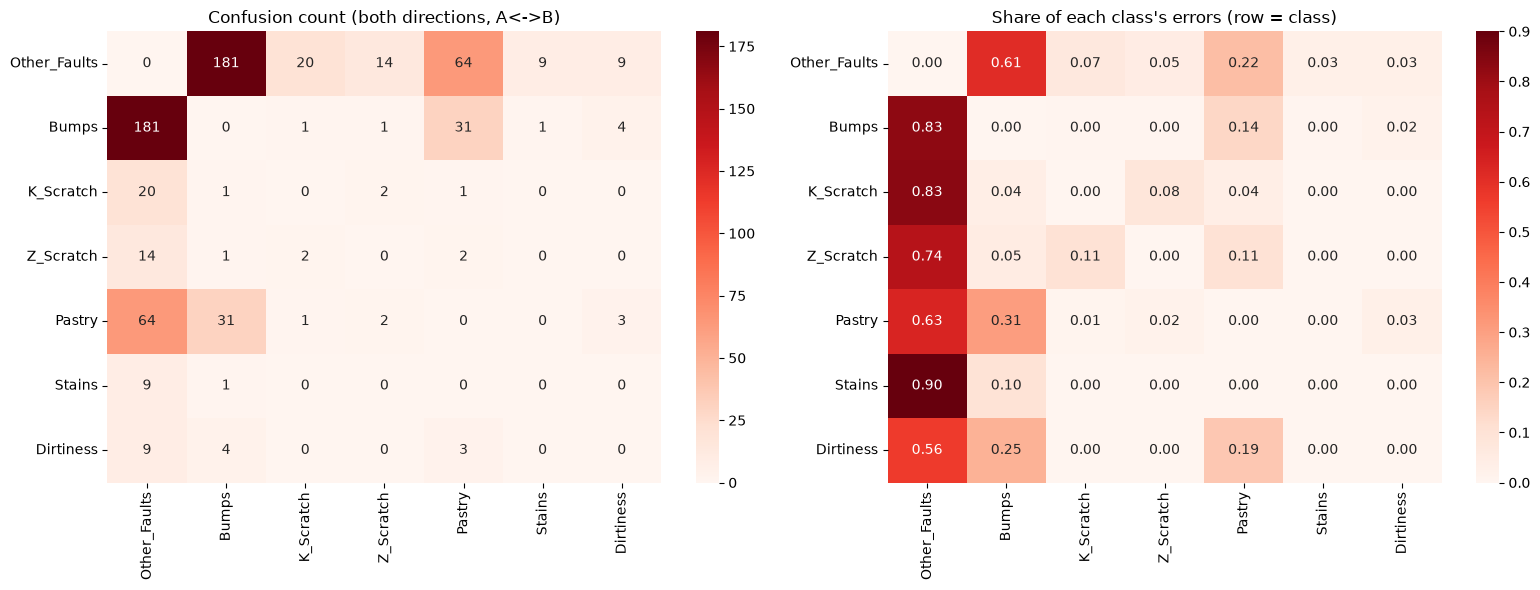

In [1]:
# =====================================================================
# 클래스별 "혼동 상대" 전체 파악
#   - 각 클래스가 누구와, 몇 건, 어느 방향으로 헷갈렸는지 모두 표로 정리
#   - 팀 공용 분할의 Train 데이터 + 5-fold CV 예측 사용 (Test는 건드리지 않음)
# =====================================================================
# %% [0] 설정
import os
os.environ["PYTHONWARNINGS"] = "ignore::UserWarning"
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import confusion_matrix

RS = 42
DATA_PATH = "/Users/adj/Downloads/steel-plate-fault-classification/data/processed/Faults_processed.csv"
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

# 비교할 모델 (원하는 걸로 바꿔도 됨)
MODEL = GradientBoostingClassifier(random_state=RS)
# MODEL = RandomForestClassifier(n_estimators=300, random_state=RS, n_jobs=-1)

df = pd.read_csv(DATA_PATH)
X = df.drop(columns=["target"])
y = df["target"]

# 팀 공용 분할
BASE_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "data" / "split" / "train_idx.csv").exists())
tr_idx = pd.read_csv(BASE_DIR / "data" / "split" / "train_idx.csv")["index"]
X_train, y_train = X.loc[tr_idx], y.loc[tr_idx]
CLASSES = y.value_counts().index.tolist()

cv = StratifiedKFold(5, shuffle=True, random_state=RS)
pred = cross_val_predict(MODEL, X_train, y_train, cv=cv, n_jobs=-1)
cm = pd.DataFrame(confusion_matrix(y_train, pred, labels=CLASSES), index=CLASSES, columns=CLASSES)
print(f"모델: {type(MODEL).__name__} | Train {len(y_train)}건, 5-fold CV 예측 기준")


# %% [1] 클래스별 혼동 상대 전체 목록
#   보낸 것(sent)    : 실제 A인데 B로 예측  -> A를 놓친 것
#   받은 것(received): 실제 B인데 A로 예측  -> A로 잘못 끌어온 것
rows = []
for a in CLASSES:
    total_err = cm.loc[a].drop(a).sum() + cm[a].drop(a).sum()
    for b in CLASSES:
        if a == b:
            continue
        sent, recv = cm.loc[a, b], cm.loc[b, a]
        if sent + recv == 0:
            continue
        rows.append({"class": a, "partner": b,
                     "sent": int(sent), "received": int(recv),
                     "total": int(sent + recv),
                     "share": (sent + recv) / total_err if total_err else 0})
partners = pd.DataFrame(rows)
partners = partners.sort_values(["class", "total"], ascending=[True, False])
partners["rank"] = partners.groupby("class").cumcount() + 1
partners["share"] = partners["share"].round(3)

for c in CLASSES:
    t = partners[partners["class"] == c][["rank", "partner", "sent", "received", "total", "share"]]
    n_err = cm.loc[c].drop(c).sum() + cm[c].drop(c).sum()
    print(f"\n■ {c}  (관여 오분류 {n_err}건 | 놓친 것 {cm.loc[c].drop(c).sum()}건, "
          f"잘못 끌어온 것 {cm[c].drop(c).sum()}건)")
    print(t.rename(columns={"sent": f"{c}→상대", "received": f"상대→{c}",
                            "total": "합계", "share": "비중"}).to_string(index=False))

partners.to_csv(f"{OUT}/confusion_partners_all.csv", index=False, encoding="utf-8-sig")


# %% [2] 한눈에 보기: 클래스별 1·2순위 상대 요약
top = partners[partners["rank"] <= 2].copy()
top["label"] = top["partner"] + " (" + (top["share"] * 100).round().astype(int).astype(str) + "%)"
summary = top.pivot(index="class", columns="rank", values="label").reindex(columns=[1, 2]).fillna("")
summary.columns = ["1순위 상대", "2순위 상대"]
print("\n[2] 클래스별 주요 혼동 상대:\n", summary.loc[CLASSES].to_string())


# %% [3] 양방향 혼동 히트맵 (A↔B 합계)
#   행 기준 비중: 각 클래스의 전체 오분류 중 그 상대가 차지하는 비율
arr = cm.to_numpy().copy()
np.fill_diagonal(arr, 0)
sym = pd.DataFrame(arr + arr.T, index=CLASSES, columns=CLASSES)
share = sym.div(sym.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(sym, annot=True, fmt="d", cmap="Reds", ax=axes[0])
axes[0].set_title("Confusion count (both directions, A<->B)")
sns.heatmap(share, annot=True, fmt=".2f", cmap="Reds", ax=axes[1])
axes[1].set_title("Share of each class's errors (row = class)")
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_partners_heatmap.png", dpi=150); plt.show()

In [3]:
import platform, logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
plt.rcParams["font.family"] = {"Darwin": "AppleGothic", "Windows": "Malgun Gothic"}.get(
    platform.system(), "NanumGothic")

① 문제 정의 가설
  · Other_Faults는 Train 1552건 중 538건(34.66%)으로 가장 많은 유형이다.
  · 그러나 데이터셋 설명과 선행 연구(Ozkat, 2022)에 따르면 단일 결함이 아니라
    6개 정의된 유형에 속하지 않는 여러 결함의 집합이다.
  · 가설: 클래스 내부 공통 특징이 약해, Confusion Matrix에서
    Other_Faults의 행(놓침)과 열(끌어옴)에 오분류가 몰릴 것이다.
  · 과제는 7클래스 분류이므로 Other_Faults는 제외하지 않는다.
  GB_baseline_7class 완료

② Confusion Matrix 오분류 집중도 (GB 기본값, Train 5-fold CV)
  전체 오분류: 343건
  Other_Faults 행 (진짜 Other → 다른 유형, 놓침)     : 130건
  Other_Faults 열 (다른 유형 → Other로 예측, 끌어옴) : 167건
  → 전체 오분류 중 Other_Faults가 관여한 비율: 86.6%
    (참고: Train에서 Other_Faults 비율은 34.7%)

  유형별 1순위 혼동 상대:
              관여 오분류        1순위 상대  1순위 비중  Other_Faults와의 혼동  Other_Faults 비중
Other_Faults     297         Bumps   0.609                  0            0.000
Bumps            219  Other_Faults   0.826                181            0.826
K_Scratch         24  Other_Faults   0.833                 20            0.833
Z_Scratch         19  Other_Faults   0.737                 14            0.737
Pastry           101 

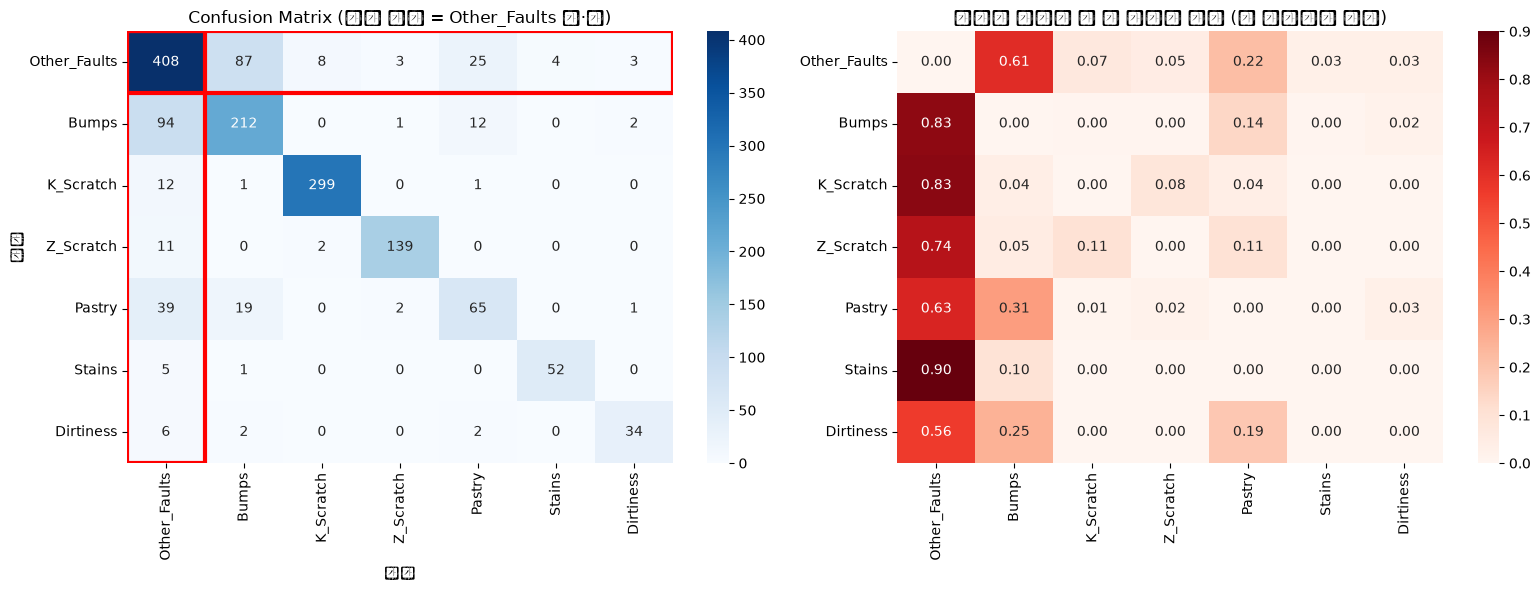


③ 가설 보강
              내부 흩어짐 (클수록 제각각)  이웃 10개 중 같은 유형 비율
Other_Faults             4.560              0.556
Bumps                    3.641              0.541
K_Scratch                4.218              0.924
Z_Scratch                3.139              0.771
Pastry                   3.966              0.410
Stains                   2.107              0.884
Dirtiness                3.542              0.661

  Other_Faults를 6개 유형 중 하나로 강제 분류하면:
Bumps        0.704
Pastry       0.158
Z_Scratch    0.065
K_Scratch    0.056
Stains       0.009
Dirtiness    0.007
  모델 확신도 평균: 0.599 (높을수록 '이 유형이 맞다'고 확신)
  GB_baseline_6class (참고, Other 제외) 완료

④ (참고) 6클래스 vs 7클래스 - 같은 6개 유형의 F1 비교
           7클래스 모델  6클래스 모델     차이
Bumps        0.659    0.884  0.225
K_Scratch    0.961    0.981  0.020
Z_Scratch    0.936    0.960  0.024
Pastry       0.563    0.748  0.185
Stains       0.912    0.948  0.036
Dirtiness    0.810    0.810  0.000
6개 유형 평균     0.807    0.889  0.082

  7클래스 Macro F1 0.7964 (Other 포함) | 6클래

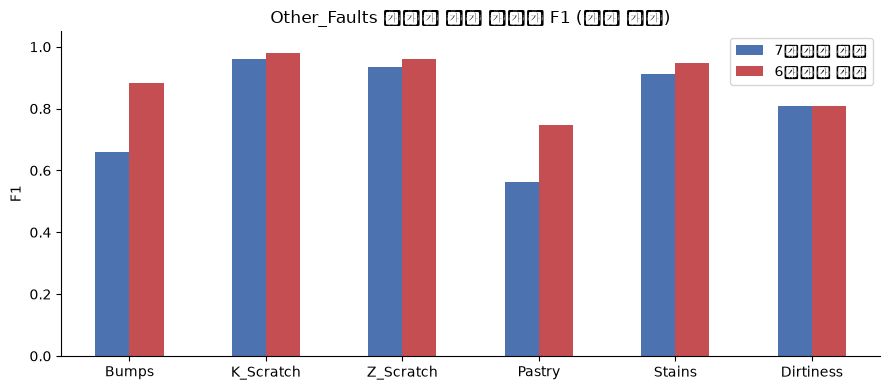

                          실험명 담당자  Macro_F1  Weighted_F1   정확도                                   비고
GB_baseline_7class_OtherCheck 안동진    0.7964       0.7788 0.779 논문반영① Other_Faults 혼합 클래스 가설 검증용 기준선

=== 팀 누적 결과 ===
                               실험명 담당자  Macro_F1  Weighted_F1    정확도                                   비고
GB+XGB_BorderlineSMOTE_SoftVoting 박태상    0.8249       0.8014 0.8015                           소프트 보팅 앙상블
               GB_BorderlineSMOTE 박태상    0.8117          NaN    NaN                           경계 집중 과대표집
    GB_baseline_7class_OtherCheck 안동진    0.7964       0.7788 0.7790 논문반영① Other_Faults 혼합 클래스 가설 검증용 기준선
                      GB_baseline 박태상    0.7960          NaN 0.7784      GradientBoosting 기본값, 불균형 처리 없음

README용 요약 (숫자는 실행 결과로 자동 채움)
Other_Faults는 Train의 34.7%를 차지하는 최다 유형이지만, 단일 결함이 아니라
여러 결함의 집합이다(Ozkat, 2022). 이에 "다른 유형과의 혼동이 많을 것"이라는 가설을 세웠다.
GB 기본 모델(5-fold CV)의 전체 오분류 343건 중 86.6%에 Other_Faults가 관여했으며,
나머지 6개 유형 중 6개의 1순위 혼동 상대가 Other_Faults였다. 내부 흩어짐

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. 파일 불러오기 (프로젝트 내 원본 또는 전처리 완료 파일 경로)
# ※ 필요시 실제 사용 중이신 파일 경로로 수정하세요.
file_path = '/Users/adj/Downloads/steel-plate-fault-classification/data/processed/Faults_processed.csv'
df = pd.read_csv(file_path)

# 2. 7개 원-핫 정답 컬럼 정의
target_cols = ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']

# 3. fault_type 타깃 컬럼 자동 판별 및 y 추출
if 'fault_type' in df.columns:
    # A) 이미 fault_type 컬럼이 있는 경우
    y = df['fault_type']
elif any(col in df.columns for col in target_cols):
    # B) 7개 정답 컬럼 중 일부/전회가 있는 경우 -> fault_type 생성
    present_targets = [col for col in target_cols if col in df.columns]
    df['fault_type'] = df[present_targets].idxmax(axis=1)
    y = df['fault_type']
else:
    # C) 예외 상황 시 현재 데이터프레임의 모든 컬럼명을 출력하여 확인
    print("⚠️ 데이터프레임에서 타깃 컬럼을 찾지 못했습니다. 현재 컬럼 목록:")
    print(df.columns.tolist())
    # 가장 마지막 열을 임시 타깃으로 설정하여 진행
    y = df.iloc[:, -1]
    print(f"-> 가장 마지막 컬럼({y.name})을 y로 대체 설정하였습니다.")

# 4. Feature X 추출 (정답 컬럼 7개와 fault_type을 X에서 완벽 제외하여 데이터 누수 방지)
drop_cols = [col for col in target_cols + ['fault_type'] if col in df.columns]
X = df.drop(columns=drop_cols)

# 5. Train / Test 80:20 층화 분할 (Stratified Split)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("\n✅ 분할 완료!")
print(f"- Feature X 모양: {X.shape}")
print(f"- X_train 모양: {X_train.shape}")
print(f"- X_test 모양: {X_test.shape}")

⚠️ 데이터프레임에서 타깃 컬럼을 찾지 못했습니다. 현재 컬럼 목록:
['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas', 'target']
-> 가장 마지막 컬럼(target)을 y로 대체 설정하였습니다.

✅ 분할 완료!
- Feature X 모양: (1941, 27)
- X_train 모양: (1552, 27)
- X_test 모양: (389, 27)


In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. 원-핫 정답 컬럼 7개 목록 정의
target_cols = ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']

# 2. 타겟(Target) 컬럼 감지 및 y 추출
if 'fault_type' in df.columns:
    y = df['fault_type']
elif 'target' in df.columns:
    # 컬럼명이 'target'인 경우 표준 명칭인 'fault_type'으로 변경
    df = df.rename(columns={'target': 'fault_type'})
    y = df['fault_type']
elif any(col in df.columns for col in target_cols):
    # 원본 7개 정답 열이 존재하는 경우 -> fault_type 새로 생성
    present_targets = [col for col in target_cols if col in df.columns]
    df['fault_type'] = df[present_targets].idxmax(axis=1)
    y = df['fault_type']
else:
    # 예외 상황
    y = df.iloc[:, -1]

# 3. Feature X 추출 (정답 열 7개, target, fault_type을 X에서 완벽 제외)
drop_cols = [col for col in target_cols + ['target', 'fault_type'] if col in df.columns]
X = df.drop(columns=drop_cols)

# 4. Train / Test 80:20 층화 분할 (Stratified Split)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("✅ 데이터 로드 및 층화 분할 완벽 완료!")
print(f"- Feature X 크기: {X.shape} (27개 변수)")
print(f"- Train 세트 크기: {X_train.shape} (80%)")
print(f"- Test 세트 크기 : {X_test.shape} (20%)")
print("\n=== Train 세트 Target 클래스 분포 (%) ===")
print((y_train.value_counts(normalize=True) * 100).round(2))

✅ 데이터 로드 및 층화 분할 완벽 완료!
- Feature X 크기: (1941, 26) (27개 변수)
- Train 세트 크기: (1552, 26) (80%)
- Test 세트 크기 : (389, 26) (20%)

=== Train 세트 Target 클래스 분포 (%) ===
fault_type
Other_Faults    34.66
Bumps           20.68
K_Scratch       20.17
Z_Scratch        9.79
Pastry           8.12
Stains           3.74
Dirtiness        2.84
Name: proportion, dtype: float64


① 고유값 수가 적은 변수 Top 10 (범주형 후보)
  TypeOfSteel_A300          고유값    2개  [np.int64(0), np.int64(1)]
  Outside_Global_Index      고유값    3개  [np.float64(0.0), np.float64(0.5), np.float64(1.0)]
  Steel_Plate_Thickness     고유값   23개  ...
  Length_of_Conveyer        고유값   80개  ...
  Maximum_of_Luminosity     고유값   95개  ...
  Minimum_of_Luminosity     고유값  152개  ...
  Log_X_Index               고유값  170개  ...
  Log_Y_Index               고유값  203개  ...
  Y_Perimeter               고유값  288개  ...
  SigmoidOfAreas            고유값  354개  ...

② Outside_Global_Index
  고유값: [np.float64(0.0), np.float64(0.5), np.float64(1.0)]
Outside_Global_Index
0.0    618
0.5     70
1.0    864

  Outside_Global_Index × 결함 유형 (건수):
target                Other_Faults  Bumps  K_Scratch  Z_Scratch  Pastry  Stains  Dirtiness
Outside_Global_Index                                                                      
0.0                            200    109        215         38       3      46          7
0.5                 

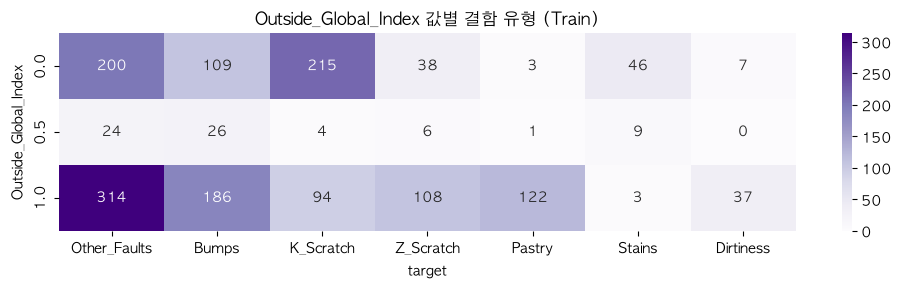


③ 범주형 목록 확정

  확정 범주형: ['TypeOfSteel_A300', 'Outside_Global_Index']  (위치 [24, 25])
  근거:
   - TypeOfSteel_A300: 0/1 강종 표시 변수 → 범주형
   - Outside_Global_Index: 고유값 3개 [np.float64(0.0), np.float64(0.5), np.float64(1.0)]뿐인 이산값, 논문(Ozkat, 2022)도 범주형으로 취급 → 범주형

④ 합성 샘플 2214건 중 범주형 열의 '존재하지 않는 값'
  TypeOfSteel_A300       원래 값 [np.float64(0.0), np.float64(1.0)] | 일반 SMOTE 119건 (5.4%) | SMOTENC 0건
    예시 (일반 SMOTE가 만든 값): [np.float64(0.122), np.float64(0.244), np.float64(0.832), np.float64(0.998), np.float64(0.919)]
  Outside_Global_Index   원래 값 [np.float64(0.0), np.float64(0.5), np.float64(1.0)] | 일반 SMOTE 175건 (7.9%) | SMOTENC 0건
    예시 (일반 SMOTE가 만든 값): [np.float64(0.117), np.float64(0.178), np.float64(0.093), np.float64(0.648), np.float64(0.635)]

⑤ 성능 비교 (GB, Train CV)
    실험명 담당자  Macro_F1  Weighted_F1   정확도    비고
GB_none 안동진    0.7988       0.7789 0.779 처리 없음
  GB_none                          0.7972 ± 0.0089
             실험명 담당자  Macro_F1  Weighted_F1    정확도               비고
GB_SMOTE_

In [14]:
# ============================================================
# 논문 반영: 범주형 변수 확정 (TypeOfSteel + Outside_Global_Index) → SMOTENC 적용
#   ① 고유값이 적은 변수 스캔 (범주형 후보 찾기)
#   ② Outside_Global_Index 값과 결함 유형 관계 확인
#   ③ 범주형 목록 확정 + 근거 출력
#   ④ 일반 SMOTE가 만드는 '존재하지 않는 값' 개수 확인
#   ⑤ GB + SMOTE vs GB + SMOTENC 성능 비교 (같은 CV, Fold 평균±std)
#   팀 공용 load_data / config / evaluate 사용, Test 미사용
# ============================================================
import os
os.environ["PYTHONWARNINGS"] = "ignore::UserWarning"
import sys, warnings, platform, logging
from pathlib import Path
warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

BASE_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "src" / "config.py").exists())
sys.path.insert(0, str(BASE_DIR / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_validate, cross_val_predict
from sklearn.metrics import f1_score, accuracy_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, SMOTENC

from load_data import load_data
from config import CV, RANDOM_STATE as R

AUTHOR = "안동진"
FIG_DIR = BASE_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams["font.family"] = {"Darwin": "AppleGothic", "Windows": "Malgun Gothic"}.get(
    platform.system(), "NanumGothic")
plt.rcParams["axes.unicode_minus"] = False

X_train, X_test, y_train, y_test = load_data()
X_train, X_test = X_train.copy(), X_test.copy()
CLASSES = y_train.value_counts().index.tolist()


# ============================================================
# ① 고유값이 적은 변수 스캔 - 범주형 후보 찾기
# ============================================================
nunq = X_train.nunique().sort_values()
print("=" * 60)
print("① 고유값 수가 적은 변수 Top 10 (범주형 후보)")
print("=" * 60)
for c, n in nunq.head(10).items():
    vals = sorted(X_train[c].unique())[:6] if n <= 6 else "..."
    print(f"  {c:25s} 고유값 {n:4d}개  {vals}")


# ============================================================
# ② Outside_Global_Index 확인
# ============================================================
ogi = "Outside_Global_Index"
print("\n" + "=" * 60)
print(f"② {ogi}")
print("=" * 60)
print(f"  고유값: {sorted(X_train[ogi].unique())}")
print(X_train[ogi].value_counts().sort_index().to_string())

ct = pd.crosstab(X_train[ogi], y_train)[CLASSES]
print(f"\n  {ogi} × 결함 유형 (건수):\n{ct.to_string()}")
print(f"\n  결함 유형별 {ogi} 구성 비율:\n"
      f"{pd.crosstab(y_train, X_train[ogi], normalize='index').loc[CLASSES].round(3).to_string()}")

fig, ax = plt.subplots(figsize=(10, 3))
sns.heatmap(ct, annot=True, fmt="d", cmap="Purples", ax=ax)
ax.set_title(f"{ogi} 값별 결함 유형 (Train)")
plt.tight_layout()
plt.savefig(FIG_DIR / "outside_global_index_x_fault.png", dpi=150, bbox_inches="tight")
plt.show()


# ============================================================
# ③ 범주형 목록 확정
#   - 강종: A300 + A400 = 1 이면 A400은 같은 정보 → 제거하고 A300 하나만 범주형
#   - Outside_Global_Index: 고유값이 몇 개뿐이면 범주형 (논문도 범주형으로 취급)
# ============================================================
print("\n" + "=" * 60)
print("③ 범주형 목록 확정")
print("=" * 60)
reasons = []
if {"TypeOfSteel_A300", "TypeOfSteel_A400"} <= set(X_train.columns):
    comp = ((X_train["TypeOfSteel_A300"] + X_train["TypeOfSteel_A400"]) == 1).all()
    print(f"  A300 + A400 = 1 (완전 보완): {comp}")
    if comp:
        X_train = X_train.drop(columns="TypeOfSteel_A400")
        X_test = X_test.drop(columns="TypeOfSteel_A400")
        reasons.append("TypeOfSteel_A400: A300과 완전 보완(합=1)이라 같은 정보 → 제거")

CAT_COLS = ["TypeOfSteel_A300"]
reasons.append("TypeOfSteel_A300: 0/1 강종 표시 변수 → 범주형")
if X_train[ogi].nunique() <= 5:
    CAT_COLS.append(ogi)
    reasons.append(f"{ogi}: 고유값 {X_train[ogi].nunique()}개 "
                   f"{sorted(X_train[ogi].unique())}뿐인 이산값, 논문(Ozkat, 2022)도 범주형으로 취급 → 범주형")
else:
    reasons.append(f"{ogi}: 고유값이 많아 수치형 유지")

NUM_COLS = [c for c in X_train.columns if c not in CAT_COLS]
X_train = X_train[NUM_COLS + CAT_COLS]          # 열 순서 고정: 수치 → 범주
X_test = X_test[NUM_COLS + CAT_COLS]
CAT_IDX = list(range(len(NUM_COLS), len(NUM_COLS) + len(CAT_COLS)))

print(f"\n  확정 범주형: {CAT_COLS}  (위치 {CAT_IDX})")
print("  근거:")
for r in reasons:
    print(f"   - {r}")


# ============================================================
# ④ 일반 SMOTE가 범주형 열에 만드는 '존재하지 않는 값'
# ============================================================
def make_scaler():
    """수치형만 표준화, 범주형은 그대로 통과 (SMOTE 거리 계산용)"""
    return ColumnTransformer([("num", StandardScaler(), NUM_COLS)], remainder="passthrough")


Xs = make_scaler().fit_transform(X_train)
X_sm, y_sm = SMOTE(k_neighbors=3, random_state=R).fit_resample(Xs, y_train)
X_nc, y_nc = SMOTENC(categorical_features=CAT_IDX, k_neighbors=3, random_state=R).fit_resample(Xs, y_train)
n_new = len(y_sm) - len(y_train)

print("\n" + "=" * 60)
print(f"④ 합성 샘플 {n_new}건 중 범주형 열의 '존재하지 않는 값'")
print("=" * 60)
bad_rows = []
for i, c in zip(CAT_IDX, CAT_COLS):
    valid = np.unique(Xs[:, i])
    bad_sm = (~np.isin(X_sm[len(y_train):, i], valid)).sum()
    bad_nc = (~np.isin(X_nc[len(y_train):, i], valid)).sum()
    bad_rows.append({"열": c, "원래 값": list(valid), "일반 SMOTE": bad_sm, "SMOTENC": bad_nc})
    print(f"  {c:22s} 원래 값 {list(valid)} | 일반 SMOTE {bad_sm}건 ({bad_sm / n_new:.1%}) | SMOTENC {bad_nc}건")
    if bad_sm:
        ex = np.round(X_sm[len(y_train):, i][~np.isin(X_sm[len(y_train):, i], valid)][:5], 3)
        print(f"    예시 (일반 SMOTE가 만든 값): {list(ex)}")


# ============================================================
# ⑤ 성능 비교 - 같은 CV, 같은 목표 건수
#   A: GB 처리 없음 / B: 일반 SMOTE (표준화 없음, 박태상 님 방식)
#   C: 일반 SMOTE + 표준화 / D: SMOTENC + 표준화
# ============================================================
def gb():
    return GradientBoostingClassifier(random_state=R)


def run(name, pipe, note=""):
    res = cross_validate(pipe, X_train, y_train, cv=CV, n_jobs=-1, scoring="f1_macro")
    pred = cross_val_predict(pipe, X_train, y_train, cv=CV, n_jobs=-1)
    row = {"실험명": name,
           "MacroF1 (fold 평균)": res["test_score"].mean(),
           "std": res["test_score"].std(),
           "MacroF1 (pooled)": f1_score(y_train, pred, average="macro"),
           "정확도": accuracy_score(y_train, pred)}
    row.update({c: f1_score(y_train == c, pred == c) for c in CLASSES})
    try:
        from evaluate import log_result
        log_result(name, y_train, pred, author=AUTHOR, note=note)
    except Exception as e:
        print(f"  (log_result 기록 생략: {e})")
    print(f"  {name:32s} {row['MacroF1 (fold 평균)']:.4f} ± {row['std']:.4f}")
    return row


print("\n" + "=" * 60)
print("⑤ 성능 비교 (GB, Train CV)")
print("=" * 60)
rows = [
    run("GB_none", gb(), "처리 없음"),
    run("GB_SMOTE_noscale", ImbPipeline([
        ("sampler", SMOTE(k_neighbors=3, random_state=R)), ("model", gb())]),
        "일반 SMOTE, 표준화 없음"),
    run("GB_SMOTE_scaled", ImbPipeline([
        ("scaler", make_scaler()),
        ("sampler", SMOTE(k_neighbors=3, random_state=R)), ("model", gb())]),
        "일반 SMOTE + 표준화"),
    run("GB_SMOTENC_scaled", ImbPipeline([
        ("scaler", make_scaler()),
        ("sampler", SMOTENC(categorical_features=CAT_IDX, k_neighbors=3, random_state=R)),
        ("model", gb())]),
        f"SMOTENC + 표준화, 범주형={CAT_COLS}"),
]
res = pd.DataFrame(rows).round(4)
print("\n" + res.to_string(index=False))
res.to_csv(BASE_DIR / "results" / "smote_vs_smotenc.csv", index=False, encoding="utf-8-sig")


# ============================================================
# README용 요약 (숫자는 실행 결과로 자동 채움)
# ============================================================
r = res.set_index("실험명")
bad_ogi = next((b["일반 SMOTE"] for b in bad_rows if b["열"] == ogi), 0)
print("\n" + "=" * 60)
print("README용 요약")
print("=" * 60)
print(f"""범주형 변수는 {', '.join(CAT_COLS)}로 지정했다. TypeOfSteel_A400은 A300과 합이 항상 1인
같은 정보라 제거했고, {ogi}는 고유값이 {X_train[ogi].nunique()}개뿐인 이산값이며 선행 연구(Ozkat, 2022)도
범주형으로 취급했다. 일반 SMOTE는 합성 샘플 {n_new}건 중 {bad_ogi}건에서 {ogi}에 원래 없는 값을 만들었으나,
범주형을 지정한 SMOTENC는 0건이었다. 성능(GB, Macro F1 fold 평균)은 일반 SMOTE
{r.loc['GB_SMOTE_noscale', 'MacroF1 (fold 평균)']:.4f}, SMOTENC {r.loc['GB_SMOTENC_scaled', 'MacroF1 (fold 평균)']:.4f}로
차이가 표준편차(약 {r['std'].mean():.3f}) 안팎이라 성능 차이보다는 '현실에 없는 데이터를 만들지 않는다'는
타당성 측면에서 SMOTENC를 채택했다.""")